# Rug Pull Detection on Solana — Multivariate EDA: Feature–Label Relationships, Redundancy, and Low-Dimensional Structure

This notebook complements `EDA_stratified.ipynb`. That notebook cleans the raw tables, builds the
q1/q2/q3 datasets and the stratified split, and already reports univariate summaries (class
balance, class-conditional missingness, single-feature AUC, class medians, a correlation heatmap).
This notebook does **not** repeat the cleaning. It loads the exported artifacts and asks the
multivariate questions:

1. How much of the label signal is carried by *whether* a feature was observed rather than by its value?
2. Which features are informative, and how stable is that across observation windows?
3. Which features are redundant or deterministic functions of each other?
4. Do the samples cluster or separate by label in 2-D projections (PCA, t-SNE, UMAP), and what drives the structure that appears?

**Data policy.** Sections 1–10 use the **train + validation** rows of the stratified split
(`full` scope) only, so nothing there can leak into the final evaluation. The single exception is
**Sections 7.7–7.8**, which visualise the chronological and stratified 70/15/15 splits including
test tokens: every transform there is fitted on training tokens only, and validation/test tokens
are merely projected through it. Preprocessing for visualisation (median imputation, scaling) is fitted on
these development rows; cross-validated reference scores in Section 8 fit all preprocessing inside
each fold.

# Setup

In [2]:
import os
# Small tables on a many-core machine: cap BLAS/OpenMP threads before numpy/sklearn load,
# otherwise thread start-up dominates (e.g. HistGradientBoosting in Section 8).
os.environ.setdefault('OMP_NUM_THREADS', '8')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '8')
os.environ.setdefault('MKL_NUM_THREADS', '8')

import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import mutual_info_score, roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*n_jobs value 1 overridden.*')
import umap  # noqa: E402  (imported after warning filters: numba is noisy)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4g}')

In [3]:
ART = './artifacts_stratified'
FIG_DIR = f'{ART}/figures/multivariate_eda'
os.makedirs(FIG_DIR, exist_ok=True)

EXPERIMENTS = ['q1', 'q2', 'q3']
WINDOW_SECONDS = {'q1': 750, 'q2': 2127, 'q3': 5585}
SEED = 42

registry = json.load(open(f'{ART}/feature_registry.json'))
NODE_NUM = registry['node_model_candidates']
GRAPH_NUM = registry['graph_model_candidates']
GRAPH_COUNTS = ['n_transfers', 'n_endpoints', 'n_edges', 'n_senders', 'n_receivers']

SHORT = {
    'volume_sell_change_percent': 'sell vol Δ%',
    'volume_buy_change_percent': 'buy vol Δ%',
    'unique_wallet_count': 'wallets',
    'unique_wallet_change_percent': 'wallets Δ%',
    'liquidity_at_observation_end': 'liquidity',
    'graph': 'graph',
}

# Variance-stabilising transforms chosen from the raw ranges (Section 3).
# Percent changes are bounded below by -100 %, so 1 + x/100 is the after/before ratio (>= 0).
pct_ratio = lambda x: np.log1p(1 + x / 100)
TRANSFORMS = {
    'volume_sell_change_percent':   ('log1p(1 + x/100)', pct_ratio),
    'volume_buy_change_percent':    ('log1p(1 + x/100)', pct_ratio),
    'unique_wallet_change_percent': ('log1p(1 + x/100)', pct_ratio),
    'unique_wallet_count':          ('log1p(x)', np.log1p),
    'liquidity_at_observation_end': ('log1p(x)', np.log1p),
    'liquidity_at_creation':        ('log1p(x)', np.log1p),
    **{c: ('log1p(x)', np.log1p) for c in GRAPH_COUNTS},
    'density':      ('log10(x)', np.log10),
    'avg_degree':   ('identity', lambda x: x),
    'first_t_frac': ('identity', lambda x: x),
    'mean_t_frac':  ('identity', lambda x: x),
}

def tf(df, col):
    return TRANSFORMS[col][1](df[col].astype(float))

In [4]:
# Colours: class identity uses the first two validated categorical slots everywhere;
# ordered things (windows, counts, time) use a single-hue sequential blue ramp;
# signed quantities (correlations, loadings) use a blue <-> gray <-> red diverging map.
CLASS_NAMES = {0: 'non-rug', 1: 'rug'}
CLASS_COLORS = {0: '#2a78d6', 1: '#eb6834'}
CLASS_PALETTE = {CLASS_NAMES[k]: v for k, v in CLASS_COLORS.items()}
WINDOW_COLORS = {'q1': '#86b6ef', 'q2': '#2a78d6', 'q3': '#104281'}
NEUTRAL = '#6b6a65'
SEQUENTIAL = LinearSegmentedColormap.from_list(
    'blue_seq', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIVERGING = LinearSegmentedColormap.from_list(
    'blue_gray_red', ['#184f95', '#6da7ec', '#f0efec', '#ee8f8e', '#b8312f'])

plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#8a8984', 'axes.linewidth': 0.8,
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
    'text.color': '#0b0b0b', 'axes.labelcolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 11, 'axes.titleweight': 'semibold', 'axes.labelsize': 10,
    'legend.frameon': False, 'legend.fontsize': 9,
})

def savefig(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')

def class_handles(y=None):
    return [Line2D([], [], marker='o', ls='', color=CLASS_COLORS[k], markersize=7,
                   label=CLASS_NAMES[k] if y is None else f'{CLASS_NAMES[k]} (n={(y == k).sum()})')
            for k in (0, 1)]

# Loading the Cleaned Artifacts

In [5]:
def load_window(q):
    """Model-ready token rows + audit-only metadata + graph features, one row per token."""
    nodes = pd.read_parquet(f'{ART}/final/full/{q}/model_nodes_raw_nan.parquet')
    extra = pd.read_parquet(f'{ART}/full/{q}/nodes.parquet',
                            columns=['token_mint', 'liquidity_at_creation', 'has_initial_mint_authority'])
    graph = pd.read_parquet(f'{ART}/final/full/{q}/model_graph_features_with_split.parquet',
                            columns=['token_mint', 'split'] + GRAPH_NUM)
    d = (nodes
         .merge(extra, on='token_mint', how='left', validate='one_to_one')
         .merge(graph.rename(columns={'split': 'graph_split'}), on='token_mint', how='left',
                validate='one_to_one'))
    assert (d['graph_split'].isna() | (d['graph_split'] == d['split'])).all(), 'split mismatch'
    d = d.drop(columns='graph_split')
    d['has_graph'] = d['n_transfers'].notna()
    d['n_observed'] = d[NODE_NUM].notna().sum(axis=1) + d['has_graph']
    d['is_pump_mint'] = d['token_mint'].str.endswith('pump')
    d['creation_utc'] = pd.to_datetime(d['creation_time'], unit='s', utc=True)
    return d

raw = {q: load_window(q) for q in EXPERIMENTS}
dev = {q: d[d['split'] != 'test'].reset_index(drop=True) for q, d in raw.items()}

for q in EXPERIMENTS:
    print(f'{q}: {len(raw[q])} tokens, {len(dev[q])} train+validation rows used, '
          f'{(raw[q].split == "test").sum()} test rows set aside')

q1: 1961 tokens, 1666 train+validation rows used, 295 test rows set aside
q2: 1798 tokens, 1523 train+validation rows used, 275 test rows set aside
q3: 1573 tokens, 1340 train+validation rows used, 233 test rows set aside


# 1. Dataset Structure, Feature Types, and Label Balance

Each row is one token observed for a fixed window after creation (q1 = 750 s, q2 = 2127 s,
q3 = 5585 s). The target `rug_pull_label` is binary and is produced by the rule-based labeller from
*post-window* liquidity and price behaviour. The candidate predictors come in two blocks:

* **token-level features** (`graph_nodes.csv`): trade-volume and wallet-count changes, wallet
  count, liquidity at the window end, and creation-time authority flags;
* **graph features** (recovered transfer graph): size counts, density, degree, and the timing of
  transfers inside the window. These exist only when at least one transfer edge was recovered.

In [6]:
structure = pd.DataFrame({q: {
    'window (s)': WINDOW_SECONDS[q],
    'tokens, all splits': len(raw[q]),
    'tokens, train+val': len(dev[q]),
    'rugs, train+val': int(dev[q].rug_pull_label.sum()),
    'rug rate': dev[q].rug_pull_label.mean(),
    'non-rug per rug': (dev[q].rug_pull_label == 0).sum() / dev[q].rug_pull_label.sum(),
    'share with recovered graph': dev[q].has_graph.mean(),
} for q in EXPERIMENTS}).T
structure

,window (s),"tokens, all splits","tokens, train+val","rugs, train+val",rug rate,non-rug per rug,share with recovered graph
q1,750,"1,961","1,666",650,0.3902,1.563,0.4688
q2,"2,127","1,798","1,523",547,0.3592,1.784,0.5325
q3,"5,585","1,573","1,340",408,0.3045,2.284,0.5709


In [7]:
FEATURE_GROUPS = (
    [(c, 'token', 'continuous, heavy-tailed, ≥ −100 %' if 'percent' in c else
      ('count' if c == 'unique_wallet_count' else 'continuous, ≥ 0, heavy-tailed')) for c in NODE_NUM]
    + [('has_initial_freeze_authority', 'token', 'boolean'),
       ('has_initial_mint_authority', 'token (audit only)', 'boolean'),
       ('liquidity_at_creation', 'token (audit only)', 'continuous, ≥ 0')]
    + [(c, 'graph', 'count' if c in GRAPH_COUNTS else
        ('fraction in [0, 1]' if c in ('density', 'first_t_frac', 'mean_t_frac') else 'continuous ≥ 1'))
       for c in GRAPH_NUM]
)
d1 = dev['q1']
feature_types = pd.DataFrame([{
    'feature': c, 'block': block, 'type': kind, 'dtype': str(d1[c].dtype),
    'distinct values (q1)': d1[c].nunique(),
    **{f'missing % {q}': 100 * dev[q][c].isna().mean() for q in EXPERIMENTS},
} for c, block, kind in FEATURE_GROUPS]).set_index('feature')
feature_types

,block,type,dtype,distinct values (q1),missing % q1,missing % q2,missing % q3
feature,,,,,,,
volume_sell_change_percent,token,"continuous, heavy-tailed, ≥ −100 %",float64,553,66.09,50.82,43.96
volume_buy_change_percent,token,"continuous, heavy-tailed, ≥ −100 %",float64,578,64.71,50.43,43.96
unique_wallet_count,token,count,float64,469,4.622,5.975,15.22
unique_wallet_change_percent,token,"continuous, heavy-tailed, ≥ −100 %",float64,571,64.65,50.43,43.88
liquidity_at_observation_end,token,"continuous, ≥ 0, heavy-tailed",float64,699,57.86,40.58,33.66
has_initial_freeze_authority,token,boolean,bool,2,0,0,0
has_initial_mint_authority,token (audit only),boolean,bool,2,0,0,0
liquidity_at_creation,token (audit only),"continuous, ≥ 0",float64,96,94.06,95.14,96.87
n_transfers,graph,count,float64,453,53.12,46.75,42.91


has_initial_mint_authority value counts (train+val):


,q1,q2,q3
has_initial_mint_authority,,,
True,1664,1522,1339
False,2,1,1


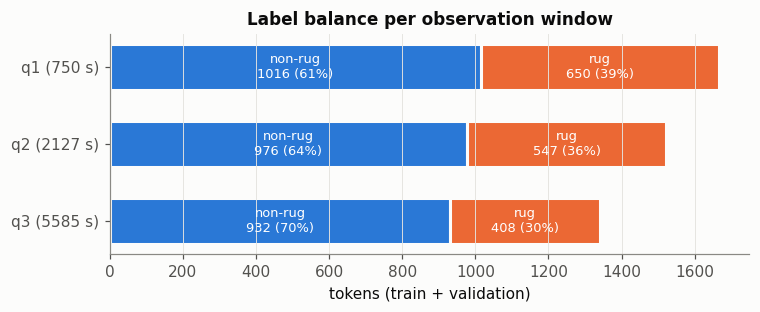

In [8]:
print('has_initial_mint_authority value counts (train+val):')
display(pd.DataFrame({q: dev[q]['has_initial_mint_authority'].value_counts() for q in EXPERIMENTS}))

fig, ax = plt.subplots(figsize=(7.5, 2.6))
for i, q in enumerate(EXPERIMENTS):
    counts = dev[q].rug_pull_label.value_counts().reindex([0, 1])
    left = 0
    for k in (0, 1):
        ax.barh(i, counts[k], left=left, color=CLASS_COLORS[k], height=0.6,
                edgecolor='#fcfcfb', linewidth=2)
        ax.text(left + counts[k] / 2, i, f'{CLASS_NAMES[k]}\n{counts[k]} ({counts[k] / counts.sum():.0%})',
                ha='center', va='center', fontsize=8.5, color='white')
        left += counts[k]
ax.set_yticks(range(3), [f'{q} ({WINDOW_SECONDS[q]} s)' for q in EXPERIMENTS])
ax.invert_yaxis()
ax.set_xlabel('tokens (train + validation)')
ax.set_title('Label balance per observation window')
ax.grid(axis='y', visible=False)
savefig(fig, '01_label_balance')
plt.show()

**<span style="color:red">Observation:</span>** The imbalance is moderate, not severe. The rug share falls from 39.0 % (q1) to 35.9 % (q2) and 30.4 % (q3), i.e. 1.6 to 2.3 non-rugs per rug, and the stratified split keeps each split within about 2 percentage points of that. Class weighting or threshold tuning, with PR-AUC reported next to ROC-AUC, is enough; resampling is not needed. The falling rate is a selection effect: tokens that rug *inside* a longer window become `IN_WINDOW_EVENT` and leave the supervised set. q1/q2/q3 are therefore different populations, not just different feature horizons. `has_initial_mint_authority` is True for all but 1 or 2 tokens per window and carries no information.

# 2. Missingness Is Itself a Feature

The token-level features have 35–67 % missing values, and the graph block is missing for roughly half
of the tokens. Before treating missing values as noise to be imputed, check whether *which features are
observed* predicts the label. Each token's missingness pattern is coded over six blocks:
the five numeric token features plus "graph recovered".

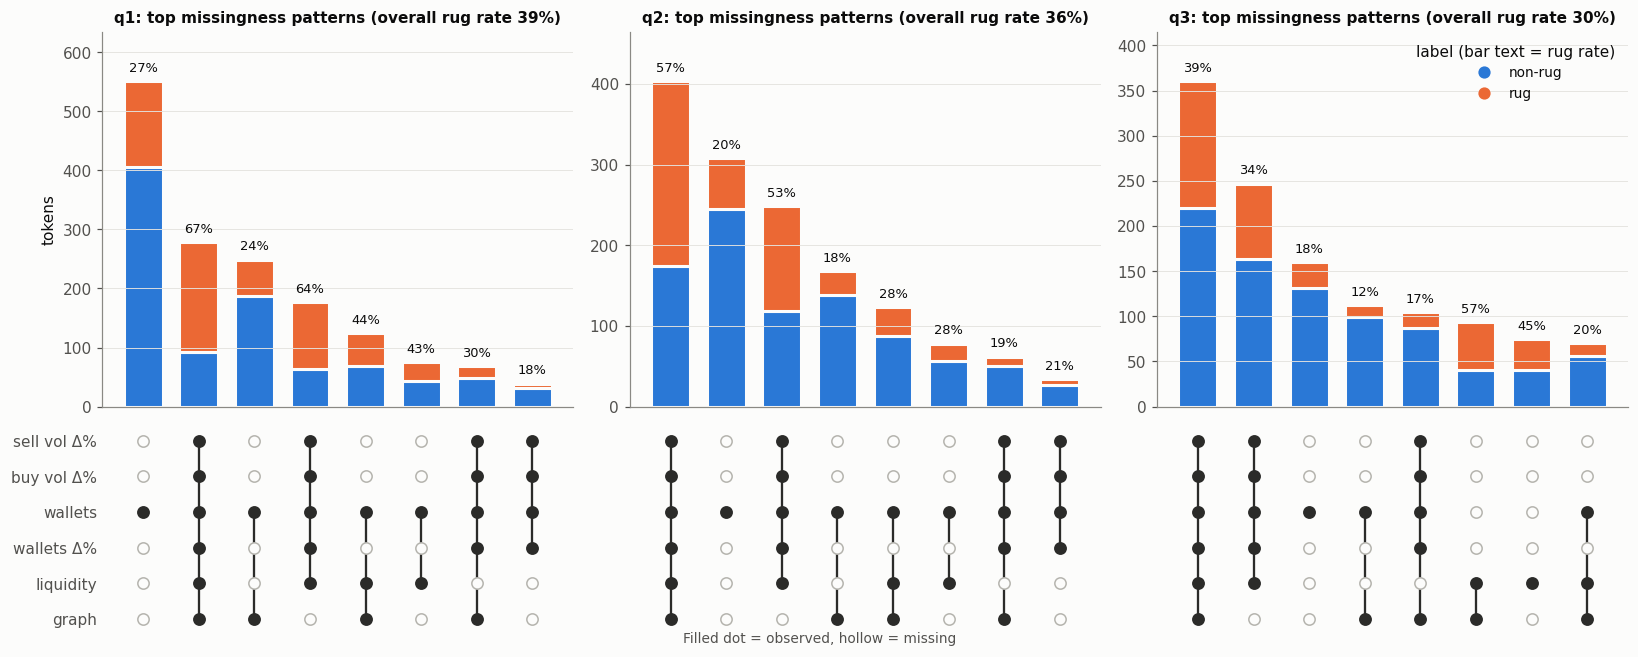

In [9]:
PATTERN_COLS = NODE_NUM + ['graph']

def presence_flags(d):
    flags = d[NODE_NUM].notna()
    flags['graph'] = d['has_graph']
    return flags

def pattern_table(d, top=8):
    key = presence_flags(d).astype(int).astype(str).agg(''.join, axis=1)
    t = (d.assign(pattern=key).groupby('pattern')['rug_pull_label']
         .agg(n='size', rugs='sum', rug_rate='mean').sort_values('n', ascending=False))
    t['share'] = t['n'] / t['n'].sum()
    return t.head(top)

fig, axes = plt.subplots(2, 3, figsize=(15, 6.2), gridspec_kw={'height_ratios': [2.3, 1.2]})
for j, q in enumerate(EXPERIMENTS):
    t = pattern_table(dev[q])
    x = np.arange(len(t))
    ax = axes[0, j]
    non = (t['n'] - t['rugs']).to_numpy()
    ax.bar(x, non, color=CLASS_COLORS[0], width=0.7, edgecolor='#fcfcfb', linewidth=2)
    ax.bar(x, t['rugs'], bottom=non, color=CLASS_COLORS[1], width=0.7, edgecolor='#fcfcfb', linewidth=2)
    for xi, (n, r) in enumerate(zip(t['n'], t['rug_rate'])):
        ax.text(xi, n + t['n'].max() * 0.02, f'{r:.0%}', ha='center', va='bottom', fontsize=8.5)
    ax.set_title(f'{q}: top missingness patterns (overall rug rate {dev[q].rug_pull_label.mean():.0%})',
                 fontsize=10)
    ax.set_xticks([])
    ax.set_ylabel('tokens' if j == 0 else '')
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, t['n'].max() * 1.15)
    if j == 2:
        ax.legend(handles=class_handles(), loc='upper right', title='label (bar text = rug rate)')

    ax = axes[1, j]
    for xi, pat in enumerate(t.index):
        present = [i for i, ch in enumerate(pat) if ch == '1']
        for i in range(len(PATTERN_COLS)):
            on = pat[i] == '1'
            ax.scatter(xi, i, s=55, color='#2b2b29' if on else '#fcfcfb',
                       edgecolor='#2b2b29' if on else '#b5b4ae', linewidth=1, zorder=3)
        if len(present) > 1:
            ax.plot([xi, xi], [min(present), max(present)], color='#2b2b29', lw=1.5, zorder=2)
    ax.set_yticks(range(len(PATTERN_COLS)), [SHORT[c] for c in PATTERN_COLS] if j == 0 else [])
    ax.set_xticks([])
    ax.tick_params(axis='y', length=0)
    ax.set_xlim(axes[0, j].get_xlim())
    ax.invert_yaxis()
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
fig.suptitle('Filled dot = observed, hollow = missing', y=0.02, fontsize=9, color='#52514e')
fig.tight_layout()
savefig(fig, '02_missingness_patterns')
plt.show()

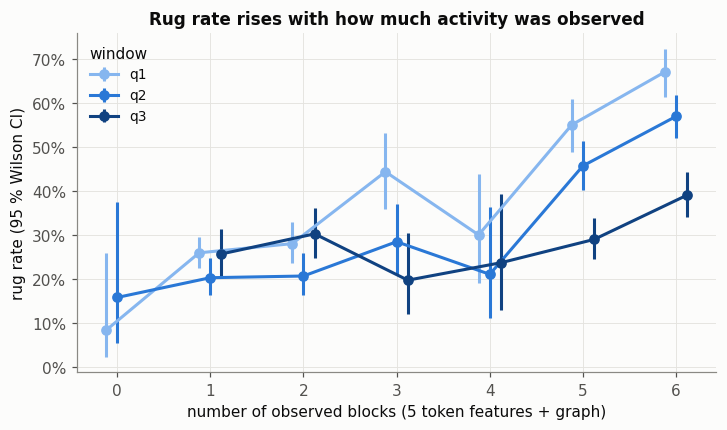

tokens         rug rate            
window         q1  q2  q3       q1    q2    q3
n_observed                                    
0              24  19 NaN    0.083 0.158   NaN
1             590 355 257    0.259 0.203 0.257
2             339 271 248     0.28 0.207 0.302
3             124 123  71    0.444 0.285 0.197
4              50  38  38      0.3 0.211 0.237
5             260 313 352     0.55 0.457  0.29
6             279 404 361     0.67 0.569 0.391

In [10]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

fig, ax = plt.subplots(figsize=(7.5, 4))
obs_rows = []
for j, q in enumerate(EXPERIMENTS):
    g = dev[q].groupby('n_observed')['rug_pull_label'].agg(['sum', 'size'])
    g = g[g['size'] >= 15]
    lo, hi = wilson(g['sum'], g['size'])
    rate = g['sum'] / g['size']
    off = (j - 1) * 0.12
    ax.errorbar(g.index + off, rate, yerr=[rate - lo, hi - rate], fmt='o-', color=WINDOW_COLORS[q],
                lw=2, ms=6, capsize=0, label=q)
    obs_rows.append(pd.DataFrame({'window': q, 'n_observed': g.index, 'tokens': g['size'],
                                  'rug rate': rate.round(3)}))
ax.set_xlabel('number of observed blocks (5 token features + graph)')
ax.set_ylabel('rug rate (95 % Wilson CI)')
ax.set_title('Rug rate rises with how much activity was observed')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.legend(title='window')
savefig(fig, '02_rug_rate_by_observed_count')
plt.show()
display(pd.concat(obs_rows).pivot(index='n_observed', columns='window', values=['tokens', 'rug rate']))

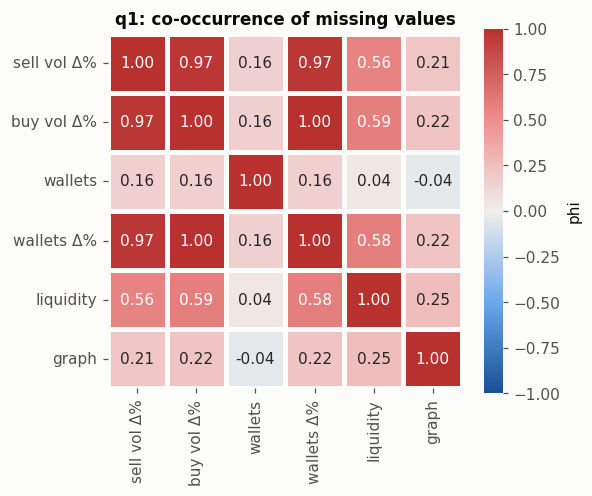

In [11]:
# Which blocks go missing together? (phi = Pearson correlation of the missing indicators)
miss_corr = (~presence_flags(dev['q1'])).astype(float).corr()
miss_corr.index = miss_corr.columns = [SHORT[c] for c in PATTERN_COLS]
fig, ax = plt.subplots(figsize=(5.2, 4.3))
sns.heatmap(miss_corr, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt='.2f', square=True,
            linewidths=2, linecolor='#fcfcfb', cbar_kws={'label': 'phi'}, ax=ax)
ax.set_title('q1: co-occurrence of missing values')
ax.grid(False)
savefig(fig, '02_missingness_cooccurrence')
plt.show()

**<span style="color:red">Observation:</span>** Missingness depends strongly on the label and has a clear structure. In q1 the largest pattern (33 % of tokens: only the wallet count is observed, with no trades, no liquidity and no graph) has a 27 % rug rate. Tokens with every block observed are 67 % rugs. The rug rate rises almost steadily with the number of observed blocks (q1: 26 % at one block, 67 % at six). The co-occurrence heatmap shows the three trade-derived features (sell/buy volume Δ, wallet Δ) are missing *together* (phi 0.97 to 1.00, one data source). Liquidity is partly coupled to them (phi ≈ 0.57), and graph presence is nearly independent (phi ≈ 0.2). So a missing value here mostly means *no trading activity was recorded in the window*. That is information, and it should be encoded (indicators or a learner that handles NaN natively) rather than imputed away. The gradient weakens as the window grows (q3: 26 % to 39 %), and q3 even has a liquidity + graph-only pattern at 57 % rugs.<br><br>**Caveat on the label definition.** `build_rule_based_labels.py` assigns label 0 as soon as liquidity does not drop. Label 1 additionally requires complete price history and persistence coverage, and 355 token-window rows (summed over q1–q3) *with* a liquidity drop ended as `UNKNOWN_*` and are absent here. Part of the "inactive ⇒ non-rug" association is therefore definitional: the non-rug class mixes healthy tokens with tokens that simply never traded. A model may learn "was this token active?" as much as "is it a rug?".

# 3. Distributions, Transformations, and Outliers

The raw scales span many orders of magnitude (sell-volume change reaches ~10⁸ %). Linear methods
(PCA, correlations, Euclidean distances in t-SNE/UMAP) would be dominated by a handful of extreme
tokens. The table compares skewness and IQR-outlier rates on the raw and transformed scales, which is
the basis for the transforms defined in Setup:

* **percent changes** → `log1p(1 + x/100)`, the log of (1 + after/before ratio), finite at −100 %;
* **counts and liquidity** → `log1p(x)`;
* **density** → `log10(x)`, because it is a strictly positive fraction spanning four decades;
* **fractions / degree** stay on their natural scale.

Rank-based statistics used later (AUC, Spearman, mutual information on quantile bins) do not depend on
these transforms; only the geometry-based methods do.

In [12]:
def iqr_outlier_mask(x, k):
    q1_, q3_ = np.nanpercentile(x, [25, 75])
    iqr = q3_ - q1_
    return (x < q1_ - k * iqr) | (x > q3_ + k * iqr)

d = dev['q1']
rows = []
for c in NODE_NUM + GRAPH_NUM:
    x = d[c].astype(float)
    t = tf(d, c)
    present = x.notna()
    far = iqr_outlier_mask(t[present].to_numpy(), 3)
    y = d.loc[present, 'rug_pull_label'].to_numpy()
    rows.append({
        'feature': c, 'transform': TRANSFORMS[c][0], 'n': int(present.sum()),
        'min': x.min(), 'median': x.median(), 'max': x.max(),
        'skew raw': stats.skew(x[present]), 'skew transformed': stats.skew(t[present]),
        '% >1.5 IQR raw': 100 * iqr_outlier_mask(x[present].to_numpy(), 1.5).mean(),
        '% >1.5 IQR transformed': 100 * iqr_outlier_mask(t[present].to_numpy(), 1.5).mean(),
        '% >3 IQR transformed': 100 * far.mean(),
        'rug rate | >3 IQR': y[far].mean() if far.any() else np.nan,
        'rug rate | rest': y[~far].mean(),
    })
dist_table = pd.DataFrame(rows).set_index('feature')
dist_table

,transform,n,min,median,max,skew raw,skew transformed,% >1.5 IQR raw,% >1.5 IQR transformed,% >3 IQR transformed,rug rate | >3 IQR,rug rate | rest
feature,,,,,,,,,,,,
volume_sell_change_percent,log1p(1 + x/100),565,-100,84.03,3.945e+07,23.62,2.929,14.34,8.142,4.425,0.84,0.5685
volume_buy_change_percent,log1p(1 + x/100),588,-100,24.27,1.65e+07,23.44,3.861,10.71,6.803,3.401,0.8,0.5792
unique_wallet_count,log1p(x),1589,0,0,"5,330",4.913,0.2892,8.244,0,0,NaN,0.4028
unique_wallet_change_percent,log1p(1 + x/100),589,-100,23.62,3.45e+04,15.15,2.599,9.508,6.791,3.056,0.8333,0.5779
liquidity_at_observation_end,log1p(x),702,0,3.709e+04,2.007e+06,5.381,-1.572,15.1,5.556,1.282,0,0.5902
n_transfers,log1p(x),781,1,185,"3,058",2.635,-0.7104,6.402,0,0,NaN,0.4328
n_endpoints,log1p(x),781,2,129,"2,906",3.188,-0.5027,8.067,0,0,NaN,0.4328
n_edges,log1p(x),781,1,161,"2,986",2.892,-0.6883,7.554,0,0,NaN,0.4328
n_senders,log1p(x),781,1,8,647,3.597,0.3719,8.323,0,0,NaN,0.4328


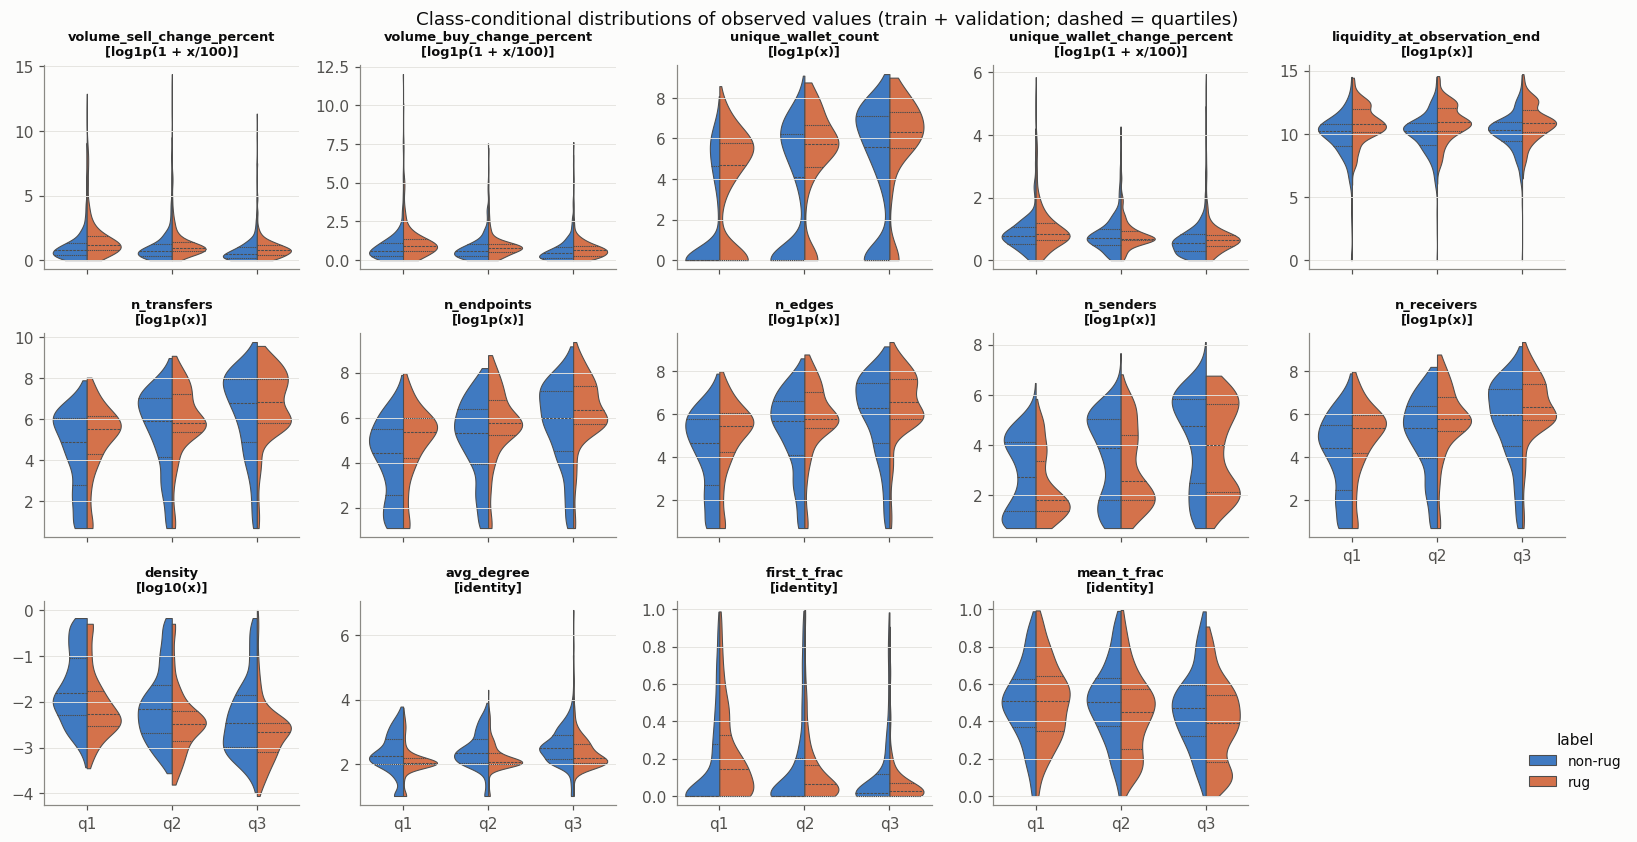

In [13]:
FEATS_ALL = NODE_NUM + GRAPH_NUM
long = pd.concat([
    pd.DataFrame({'window': q, 'feature': c, 'value': tf(dev[q], c),
                  'class': dev[q]['rug_pull_label'].map(CLASS_NAMES)}).dropna()
    for q in EXPERIMENTS for c in FEATS_ALL
], ignore_index=True)
g = sns.catplot(data=long, kind='violin', x='window', y='value', hue='class', col='feature',
                col_order=FEATS_ALL, col_wrap=5, split=True, inner='quart', cut=0,
                density_norm='width', sharey=False, height=2.55, aspect=1.15,
                hue_order=['non-rug', 'rug'], palette=CLASS_PALETTE, linewidth=0.7)
for ax, c in zip(g.axes.flat, FEATS_ALL):
    ax.set_title(f'{c}\n[{TRANSFORMS[c][0]}]', fontsize=8.5)
    ax.set_xlabel('')
    ax.set_ylabel('')
g.figure.suptitle('Class-conditional distributions of observed values (train + validation; '
                  'dashed = quartiles)', y=1.02)
sns.move_legend(g, 'lower right', bbox_to_anchor=(0.97, 0.08), title='label')
savefig(g.figure, '03_class_conditional_violins')
plt.show()

**<span style="color:red">Observation:</span>** Raw skewness of 2 to 24 falls to about 4 or less after transformation, and the IQR-outlier share of the trade features drops from 10–14 % to 7–8 %. The extreme values that remain are real behaviour, not data errors. Tokens beyond 3 × IQR on the transformed sell-volume, buy-volume and wallet-Δ scales are 80–84 % rugs in q1, against about 58 % for other tokens with trade data. Explosive volume growth inside the window is itself a rug signal, so these points should be kept, not clipped. Liquidity has a thin low tail near 0, and its >3 × IQR members are all non-rugs.<br><br>The violins show the class differences directly:<br>* `unique_wallet_count` is bimodal, with a spike at 0 (no buyers, mostly non-rug).<br>* Rug graphs have fewer senders and an average degree close to 2, which is a star: one distributor fanning out to many receivers. Their density is lower too.<br>* In q2/q3, rug transfers happen earlier in the window (lower `mean_t_frac`).<br><br>These shapes are consistent across the three windows; mainly the overall graph size grows with the window.

# 4. Feature–Label Association

Three complementary, rank-based measures per feature and window:

* **AUC on observed values** (with 95 % bootstrap CI): probability that a random rug token has a
  higher value than a random non-rug token. 0.5 = no separation; values below 0.5 mean *lower* values
  indicate rugs. Mann–Whitney p-values are Benjamini–Hochberg-adjusted within each window.
* **Mutual information** (bits) between the label and the feature discretised into deciles **plus a
  separate "missing" bin**. This captures value and missingness information together, plus
  non-monotone effects. Its **missingness share** is the MI of the missing/observed flag alone. The
  95th percentile of a 200-permutation null is reported to separate signal from small-sample bias.
* **Rug rate when missing vs observed.**

The label entropy is H(y) ≈ 0.88–0.96 bits, so an MI of 0.05 bits is ~5 % of the label uncertainty.

In [14]:
EXTRA_ASSOC = ['liquidity_at_creation', 'has_initial_freeze_authority', 'has_initial_mint_authority',
               'has_graph', 'is_pump_mint']
TO_BITS = 1 / np.log(2)

def bootstrap_auc_ci(x, y, n_boot=500, seed=SEED):
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if y[i].min() != y[i].max():
            aucs.append(roc_auc_score(y[i], x[i]))
    return np.percentile(aucs, [2.5, 97.5])

def discretise(x, n_bins=10):
    x = pd.Series(x).astype(float)
    codes = pd.Series(-1, index=x.index)
    present = x.notna()
    if x[present].nunique() <= n_bins:
        codes[present] = pd.factorize(x[present], sort=True)[0]
    else:
        codes[present] = pd.qcut(x[present], n_bins, labels=False, duplicates='drop')
    return codes.to_numpy()

def mi_parts(x, y, n_perm=200, seed=SEED):
    codes = discretise(x)
    mi = mutual_info_score(y, codes) * TO_BITS
    mi_missing = mutual_info_score(y, codes == -1) * TO_BITS
    rng = np.random.default_rng(seed)
    null = [mutual_info_score(rng.permutation(y), codes) * TO_BITS for _ in range(n_perm)]
    return mi, mi_missing, np.percentile(null, 95)

def bh(p):
    p = pd.Series(p, dtype=float)
    pv = p.dropna().sort_values()
    adj = (pv * len(pv) / np.arange(1, len(pv) + 1))[::-1].cummin()[::-1].clip(upper=1)
    return adj.reindex(p.index)

def association_table(d):
    y_all = d['rug_pull_label'].to_numpy()
    rows = []
    for c in FEATS_ALL + EXTRA_ASSOC:
        x = d[c]
        present = x.notna().to_numpy()
        xv, yv = x[present].astype(float).to_numpy(), y_all[present]
        row = {'feature': c, 'n observed': int(present.sum()), 'missing %': 100 * (1 - present.mean())}
        if len(np.unique(xv)) > 1:
            row['AUC'] = roc_auc_score(yv, xv)
            row['AUC lo'], row['AUC hi'] = bootstrap_auc_ci(xv, yv)
            row['MW p'] = stats.mannwhitneyu(xv[yv == 1], xv[yv == 0]).pvalue
        row['rug | missing'] = y_all[~present].mean() if (~present).any() else np.nan
        row['rug | observed'] = yv.mean()
        row['MI bits'], row['MI from missingness'], row['MI null 95%'] = mi_parts(x, y_all)
        rows.append(row)
    t = pd.DataFrame(rows).set_index('feature')
    t['MW q (BH)'] = bh(t['MW p'])
    t['MI > null'] = t['MI bits'] > t['MI null 95%']
    return t

assoc = {q: association_table(dev[q]) for q in EXPERIMENTS}
cols = ['n observed', 'missing %', 'AUC', 'AUC lo', 'AUC hi', 'MW q (BH)', 'rug | missing',
        'rug | observed', 'MI bits', 'MI from missingness', 'MI null 95%', 'MI > null']
assoc['q1'][cols].sort_values('MI bits', ascending=False)

,n observed,missing %,AUC,AUC lo,AUC hi,MW q (BH),rug | missing,rug | observed,MI bits,MI from missingness,MI null 95%,MI > null
feature,,,,,,,,,,,,
liquidity_at_observation_end,702,57.86,0.666,0.6222,0.7054,3.861e-13,0.25,0.5826,0.1127,0.08244,0.007774,True
volume_buy_change_percent,588,64.71,0.6186,0.5702,0.6665,1.646e-06,0.2829,0.5867,0.08025,0.06357,0.008886,True
volume_sell_change_percent,565,66.09,0.662,0.6141,0.7113,1.29e-10,0.2925,0.5805,0.07753,0.05594,0.007738,True
avg_degree,781,53.12,0.3723,0.3318,0.4126,2.139e-09,0.3525,0.4328,0.07644,0.00486,0.007749,True
unique_wallet_count,1589,4.622,0.6673,0.6421,0.692,1.261e-32,0.1299,0.4028,0.07211,0.01156,0.004438,True
unique_wallet_change_percent,589,64.65,0.5607,0.5174,0.6075,0.01339,0.2832,0.5857,0.07175,0.06309,0.007211,True
density,781,53.12,0.3366,0.2978,0.3684,4.455e-14,0.3525,0.4328,0.04292,0.00486,0.00766,True
liquidity_at_creation,99,94.06,0.7414,0.6163,0.8576,0.0006495,0.3663,0.7677,0.0372,0.02696,0.008591,True
first_t_frac,781,53.12,0.6129,0.5751,0.6509,2.835e-08,0.3525,0.4328,0.03586,0.00486,0.00547,True


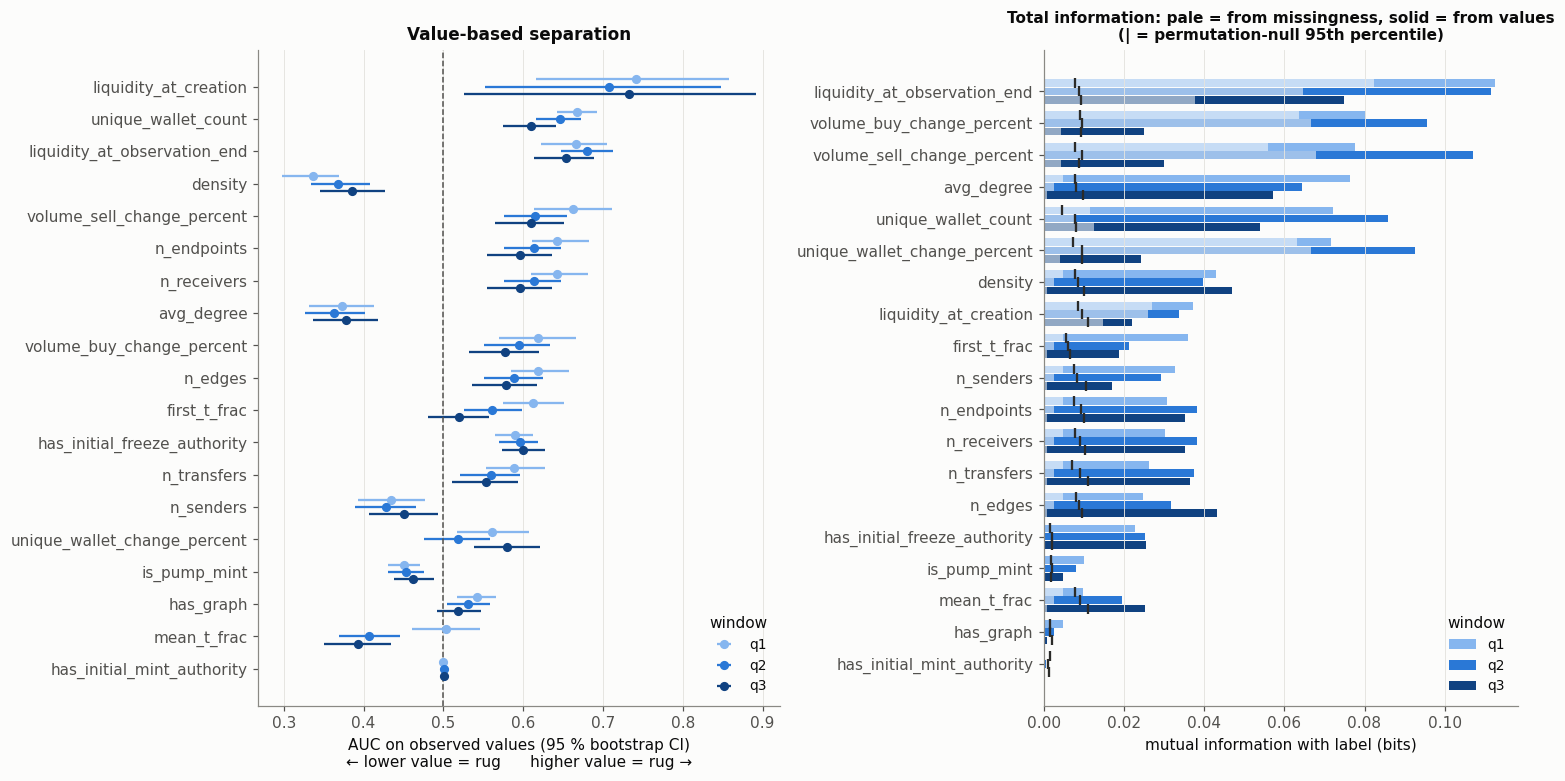

In [15]:
auc_order = (assoc['q1']['AUC'] - 0.5).abs().dropna().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 7.2), gridspec_kw={'width_ratios': [1.1, 1]})

ax = axes[0]
for j, q in enumerate(EXPERIMENTS):
    t = assoc[q].reindex(auc_order)
    yy = np.arange(len(t)) + (1 - j) * 0.22   # q1 drawn on top within each feature row
    ax.errorbar(t['AUC'], yy, xerr=[t['AUC'] - t['AUC lo'], t['AUC hi'] - t['AUC']], fmt='o',
                color=WINDOW_COLORS[q], ms=5, lw=1.5, capsize=0, label=q)
ax.axvline(0.5, color='#52514e', lw=1, ls='--')
ax.set_yticks(range(len(auc_order)), auc_order)
ax.set_xlabel('AUC on observed values (95 % bootstrap CI)\n← lower value = rug      higher value = rug →')
ax.set_title('Value-based separation')
ax.legend(title='window', loc='lower right')
ax.grid(axis='y', visible=False)

ax = axes[1]
mi_order = assoc['q1']['MI bits'].sort_values().index
for j, q in enumerate(EXPERIMENTS):
    t = assoc[q].reindex(mi_order)
    yy = np.arange(len(t)) + (1 - j) * 0.26
    ax.barh(yy, t['MI from missingness'], height=0.24, color=WINDOW_COLORS[q], alpha=0.45)
    ax.barh(yy, t['MI bits'] - t['MI from missingness'], left=t['MI from missingness'], height=0.24,
            color=WINDOW_COLORS[q], label=q)
    ax.scatter(t['MI null 95%'], yy, marker='|', color='#2b2b29', s=40, zorder=3)
ax.set_yticks(range(len(mi_order)), mi_order)
ax.set_xlabel('mutual information with label (bits)')
ax.set_title('Total information: pale = from missingness, solid = from values\n'
             '(| = permutation-null 95th percentile)', fontsize=10)
ax.legend(title='window', loc='lower right')
ax.grid(axis='y', visible=False)
fig.tight_layout()
savefig(fig, '04_feature_label_association')
plt.show()

In [16]:
# Cross-window stability: does each feature keep the same direction and strength?
stability = pd.concat({q: assoc[q][['AUC', 'MI bits', 'MI from missingness']] for q in EXPERIMENTS},
                      axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
stability.sort_values(('MI bits', 'q1'), ascending=False)

AUC                 MI bits                     MI from missingness                   
                                 q1     q2     q3        q1        q2        q3                  q1       q2        q3
feature                                                                                                               
liquidity_at_observation_end  0.666 0.6804 0.6534    0.1127    0.1117   0.07487             0.08244  0.06476   0.03762
volume_buy_change_percent    0.6186 0.5953 0.5769   0.08025   0.09555   0.02506             0.06357  0.06653  0.004224
volume_sell_change_percent    0.662 0.6142 0.6098   0.07753     0.107    0.0299             0.05594  0.06792  0.004224
avg_degree                   0.3723 0.3631 0.3783   0.07644   0.06435   0.05705             0.00486 0.002567 0.0007883
unique_wallet_count          0.6673 0.6464 0.6098   0.07211   0.08585   0.05387             0.01156 0.007447   0.01242
unique_wallet_change_percent 0.5607 0.5189 0.5796   0.07175   0.09248   0.02424             0.06309  0.06653  0.004116
density                      0.3366 0.3682 0.3849   0.04292   0.03969     0.047             0.00486 0.002567 0.0007883
liquidity_at_creation        0.7414 0.7079 0.7321    0.0372   0.03359   0.02196             0.02696    0.026   0.01475
first_t_frac                 0.6129 0.5607 0.5195   0.03586   0.02124   0.01877             0.00486 0.002567 0.0007883
n_senders                    0.4337 0.4275 0.4507   0.03274   0.02932   0.01698             0.00486 0.002567 0.0007883
n_endpoints                  0.6429 0.6136 0.5962   0.03067   0.03821   0.03524             0.00486 0.002567 0.0007883
n_receivers                  0.6423 0.6134 0.5962    0.0302   0.03832   0.03511             0.00486 0.002567 0.0007883
n_transfers                  0.5881 0.5593  0.553   0.02622   0.03739   0.03648             0.00486 0.002567 0.0007883
n_edges                      0.6185 0.5881 0.5785   0.02484   0.03179   0.04313             0.00486 0.002567 0.0007883
has_initial_freeze_authority 0.5899 0.5959 0.6003   0.02275   0.02514   0.02543                   0        0         0
is_pump_mint                   0.45 0.4535 0.4615  0.009911  0.008022  0.004831                   0        0         0
mean_t_frac                  0.5032 0.4068 0.3933  0.009715   0.01941   0.02516             0.00486 0.002567 0.0007883
has_graph                     0.542  0.531 0.5178   0.00486  0.002567 0.0007883                   0        0         0
has_initial_mint_authority   0.4997 0.5005 0.5005 4.289e-05 0.0004217 0.0003911                   0        0         0

**<span style="color:red">Observation:</span>** **Most informative single features (q1, MI including missingness):**<br>* liquidity at window end: 0.11 bits, 73 % of it from whether liquidity was observed at all;<br>* buy/sell volume Δ: about 0.08 bits, mostly from missingness;<br>* `avg_degree`: 0.08 bits, almost all from its values;<br>* `unique_wallet_count`: 0.07 bits, from its values.<br><br>**On observed values**, the clearest separators are `unique_wallet_count` (AUC 0.67), liquidity at window end (0.67) and sell volume Δ (0.66). In the other direction (lower value means rug) they are density (0.34), `avg_degree` (0.37) and `n_senders` (0.43). All are significant after BH adjustment and keep the same direction in all three windows.<br><br>**Uninformative or unusable:** `has_initial_mint_authority` (constant), `has_graph` on its own (MI ≈ 0.005 bits) and `mean_t_frac` in q1 (AUC 0.50, though it becomes informative in q2/q3 at 0.41/0.39). `liquidity_at_creation` has the highest AUC (0.74) but on only 99 tokens (94 % missing); it is outside the registry and should stay audit-only.<br><br>**Drift across windows:** the trade-feature signal fades with window length. Sell volume Δ carries 0.078, 0.107 and 0.030 bits in q1/q2/q3, and its missingness share collapses in q3 (0.004 bits) because most tokens that survive to 5585 s have trades. The graph features keep or gain information as the window grows. No feature with adequate n exceeds AUC 0.68, so a useful model has to combine many weak signals.

# 5. Redundancy: Correlated and Deterministic Features

Spearman correlation is used because the features are skewed and the relationships are monotone
but not linear. Correlations are pairwise-complete on the train + validation rows, so graph–graph
cells are computed on the ~50 % of tokens with a recovered graph. Features are ordered by
average-linkage clustering on the distance 1 − |ρ|.

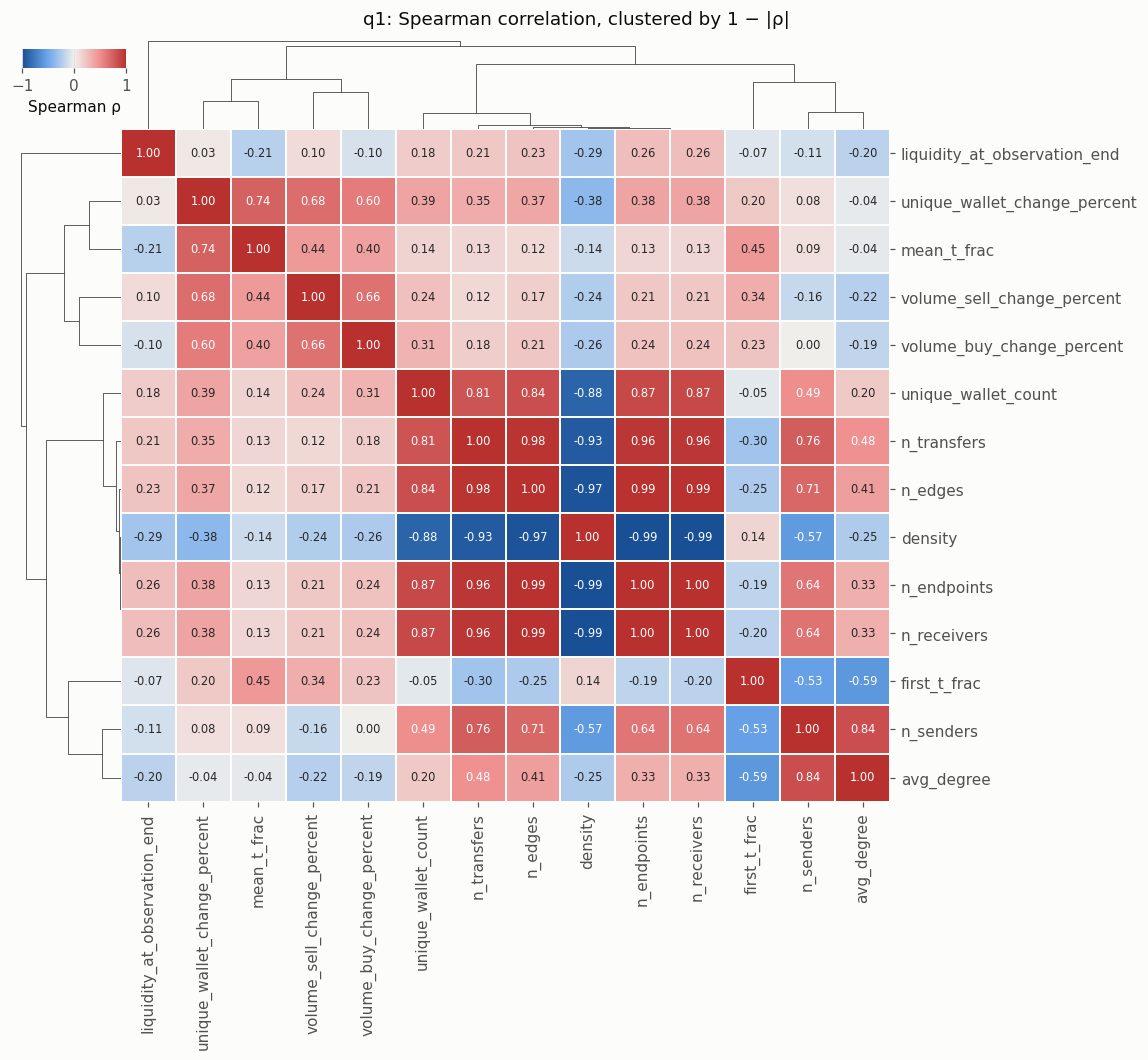

In [17]:
def spearman_clusters(d, threshold=0.85):
    corr = d[FEATS_ALL].corr(method='spearman', min_periods=30)
    dist = (1 - corr.abs()).fillna(1).to_numpy()
    np.fill_diagonal(dist, 0)
    link = hierarchy.linkage(squareform(dist, checks=False), method='average')
    labels = hierarchy.fcluster(link, t=1 - threshold, criterion='distance')
    return corr, link, pd.Series(labels, index=FEATS_ALL)

corr_q1, link_q1, clusters_q1 = spearman_clusters(dev['q1'])
cg = sns.clustermap(corr_q1, row_linkage=link_q1, col_linkage=link_q1, cmap=DIVERGING, vmin=-1, vmax=1,
                    annot=True, fmt='.2f', annot_kws={'fontsize': 7.5}, linewidths=1,
                    linecolor='#fcfcfb', figsize=(10.5, 9.5), dendrogram_ratio=0.12,
                    cbar_pos=(0.02, 0.955, 0.09, 0.018),
                    cbar_kws={'label': 'Spearman ρ', 'orientation': 'horizontal'})
cg.ax_heatmap.grid(False)
cg.ax_heatmap.set_xlabel('')
cg.ax_heatmap.set_ylabel('')
cg.figure.suptitle('q1: Spearman correlation, clustered by 1 − |ρ|', y=1.01)
savefig(cg.figure, '05_spearman_clustermap_q1')
plt.show()

In [18]:
# Redundancy groups (|ρ| >= 0.85) per window, and exact algebraic identities.
for q in EXPERIMENTS:
    _, _, cl = spearman_clusters(dev[q])
    groups = [sorted(g.index) for _, g in cl.groupby(cl) if len(g) > 1]
    print(f'{q}: groups with |ρ| >= 0.85 ->', groups)

g1 = dev['q1'][dev['q1'].has_graph]
identities = {
    'avg_degree == 2 * n_edges / n_endpoints':
        np.allclose(g1.avg_degree, 2 * g1.n_edges / g1.n_endpoints),
    'density == n_edges / (n_endpoints * (n_endpoints - 1))':
        np.allclose(g1.density, g1.n_edges / (g1.n_endpoints * (g1.n_endpoints - 1))),
    'median(n_endpoints - n_receivers)': (g1.n_endpoints - g1.n_receivers).median(),
    'share with n_endpoints - n_receivers <= 1': ((g1.n_endpoints - g1.n_receivers) <= 1).mean(),
    'median(n_transfers - n_edges)': (g1.n_transfers - g1.n_edges).median(),
}
pd.Series(identities, name='q1 graph rows').to_frame()

q1: groups with |ρ| >= 0.85 -> [['density', 'n_edges', 'n_endpoints', 'n_receivers', 'n_transfers', 'unique_wallet_count']]
q2: groups with |ρ| >= 0.85 -> [['density', 'n_edges', 'n_endpoints', 'n_receivers', 'n_transfers', 'unique_wallet_count']]
q3: groups with |ρ| >= 0.85 -> [['density', 'n_edges', 'n_endpoints', 'n_receivers', 'n_transfers', 'unique_wallet_count'], ['unique_wallet_change_percent', 'volume_buy_change_percent', 'volume_sell_change_percent']]


,q1 graph rows
avg_degree == 2 * n_edges / n_endpoints,True
density == n_edges / (n_endpoints * (n_endpoints - 1)),True
median(n_endpoints - n_receivers),1
share with n_endpoints - n_receivers <= 1,0.9629
median(n_transfers - n_edges),4


In [19]:
# One representative per redundancy group is kept for the geometric analyses that follow.
# Size group {n_transfers, n_edges, n_endpoints, n_receivers, density} -> n_receivers
#   (highest AUC in the group; n_endpoints is n_receivers + the single distributor wallet, density ~ 2/size).
# avg_degree is an exact function of n_edges and n_endpoints; its information is mostly the sender
#   concentration, so n_senders represents it.
DR_GRAPH = ['n_receivers', 'n_senders', 'first_t_frac', 'mean_t_frac']
DR_NODE = NODE_NUM
DR_BOOL = ['has_initial_freeze_authority']
print('Geometric-analysis feature set:', DR_NODE + DR_GRAPH + DR_BOOL)

Geometric-analysis feature set: ['volume_sell_change_percent', 'volume_buy_change_percent', 'unique_wallet_count', 'unique_wallet_change_percent', 'liquidity_at_observation_end', 'n_receivers', 'n_senders', 'first_t_frac', 'mean_t_frac', 'has_initial_freeze_authority']


**<span style="color:red">Observation:</span>** The Spearman clustering finds one dominant redundancy group in every window: {`n_transfers`, `n_edges`, `n_endpoints`, `n_receivers`, `density`, `unique_wallet_count`}. All pairs have |ρ| ≥ 0.81, and the graph counts among themselves have |ρ| ≥ 0.96. Several of these relationships are **exact**: `avg_degree = 2·n_edges / n_endpoints`, `density = n_edges / (n_endpoints·(n_endpoints − 1))`, and `n_endpoints − n_receivers ≤ 1` for 96 % of graphs (the receivers plus one distributor). Density is therefore close to an inverse of graph size.<br><br>The nine graph features carry roughly **four independent dimensions**:<br>* size;<br>* sender concentration (`n_senders` / `avg_degree`, ρ = 0.84);<br>* first-transfer timing;<br>* mean-transfer timing.<br><br>On the token side, the three trade-derived Δ features correlate at ρ = 0.60–0.74 and merge into one group in q3. Wallet Δ % tracks `mean_t_frac` (ρ = 0.74), because both describe activity growth late in the window.<br><br>For linear or distance-based models, keep one representative per group; the projections below use `n_receivers`, `n_senders`, `first_t_frac` and `mean_t_frac`. Tree ensembles tolerate the redundancy, but split-based importance gets spread across the near-copies, so importance rankings should be read per group, not per column.

# 6. Pair Plot of the Non-Redundant, Informative Features

Restricted to q1 tokens with a recovered graph, so every panel has a non-trivial sample. The axes use
the transformed scales. The diagonal shows class-wise densities, normalised separately per class so
the minority class stays visible.

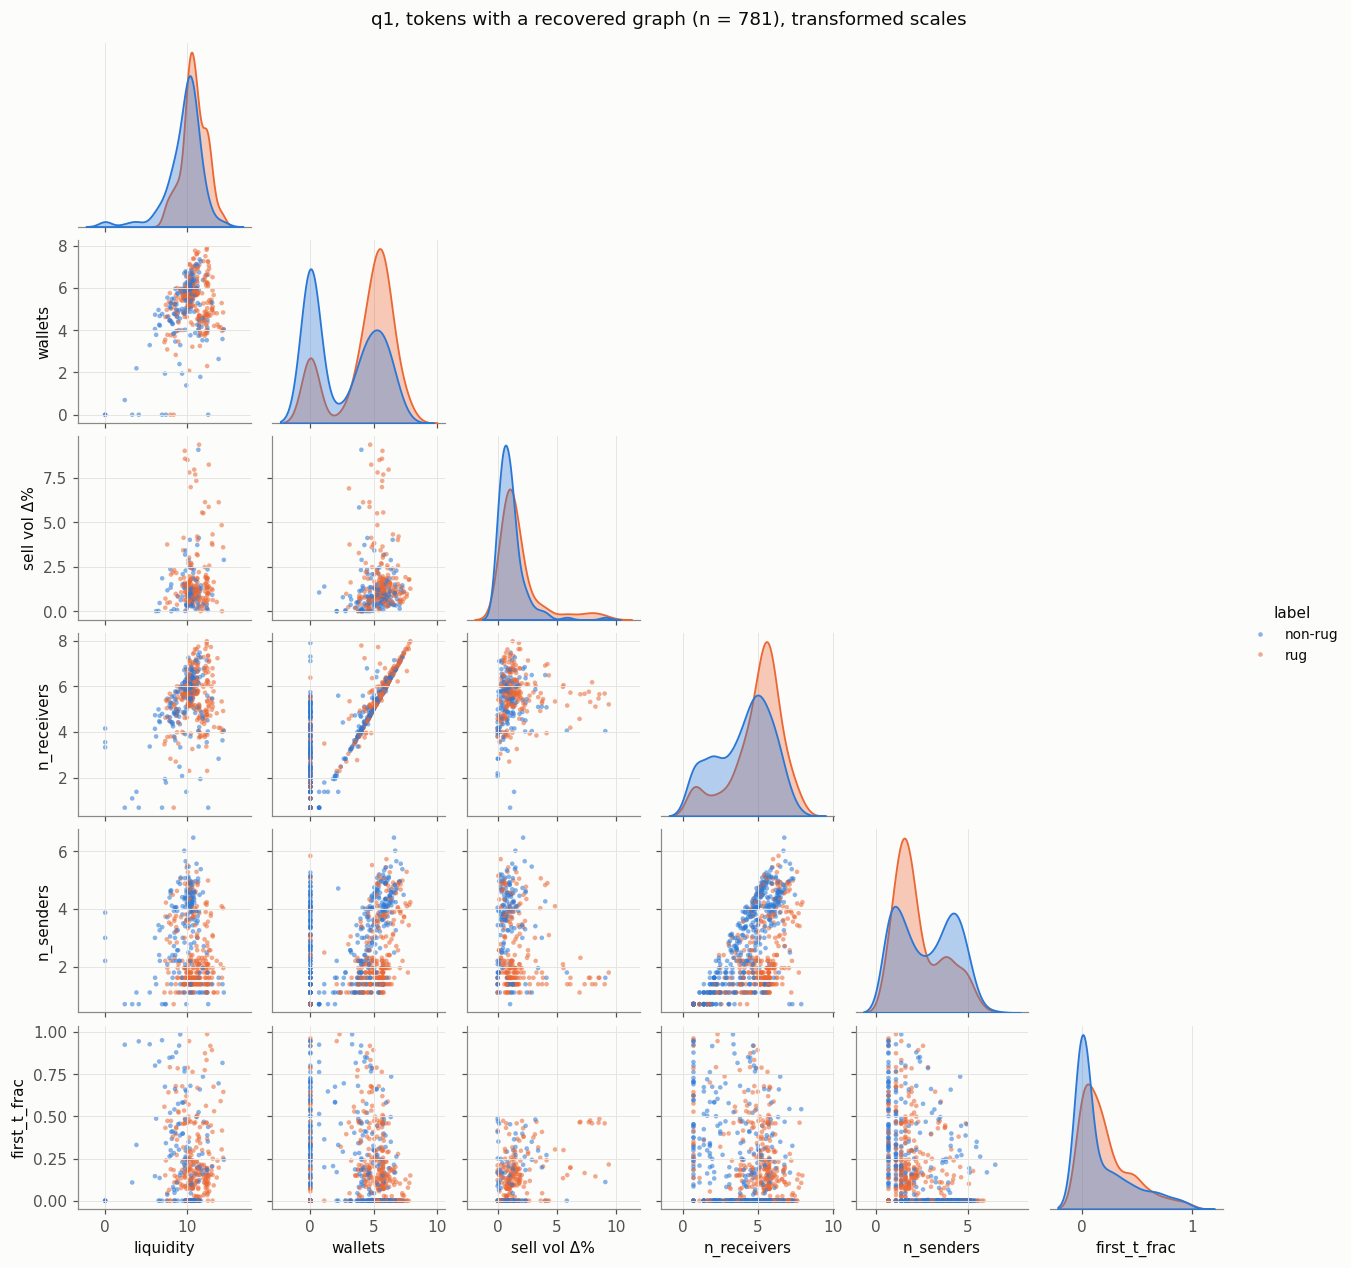

In [20]:
PAIR = ['liquidity_at_observation_end', 'unique_wallet_count', 'volume_sell_change_percent',
        'n_receivers', 'n_senders', 'first_t_frac']
pp = dev['q1'][dev['q1'].has_graph]
pp_df = pd.DataFrame({SHORT.get(c, c): tf(pp, c) for c in PAIR})
pp_df['label'] = pp['rug_pull_label'].map(CLASS_NAMES).to_numpy()
g = sns.pairplot(pp_df.sample(frac=1, random_state=SEED), hue='label', hue_order=['non-rug', 'rug'],
                 palette=CLASS_PALETTE, corner=True, height=1.9,
                 plot_kws={'s': 9, 'alpha': 0.55, 'linewidth': 0},
                 diag_kws={'common_norm': False, 'fill': True, 'alpha': 0.35, 'linewidth': 1.2})
g.figure.suptitle(f'q1, tokens with a recovered graph (n = {len(pp)}), transformed scales', y=1.01)
savefig(g.figure, '06_pairplot_q1_graph')
plt.show()

**<span style="color:red">Observation:</span>** The most informative panel is **`n_receivers` × `n_senders`**. Rugs sit in a band with many receivers but only about 2 to 10 senders (log1p ≈ 1 to 2.3): one or a few wallets distributing tokens to many others. Non-rugs with large graphs also have many senders, which looks more like organic two-way trading. This is the clearest 2-D separation in the data, and it is invisible to either feature alone. A second pattern is a vertical stripe in **`wallets` × `n_receivers`**: tokens with `unique_wallet_count = 0` (no swap buyers) but tens to hundreds of transfer receivers. These are almost all non-rugs and look like airdrop-style distributions without trading. Outside that stripe, `wallets` ≈ `n_receivers`, which confirms the redundancy above. Liquidity and sell volume Δ shift the rug class to the right but with heavy overlap.

# 7. Dimensionality Reduction: Do the Classes Separate in 2-D?

**Preprocessing for the projections.** The transforms come from Section 3, and only the non-redundant
features from Section 5 are used. Missing token features get a **missing indicator** (Section 2
showed missingness is informative) and are then median-imputed. Graph size counts are set to 0 for
tokens without a recovered graph (zero recovered transfers); graph timing features are
median-imputed with a `has_graph` indicator. All columns are standardised. There are no categorical
predictors to encode beyond the booleans, which enter as 0/1.

Three views separate the effect of missingness from the effect of values:

| view | rows | columns |
|---|---|---|
| **A: all tokens** | every train+val token | values + missing indicators |
| **B: graph recovered** | tokens with ≥ 1 recovered edge | values + missing indicators |
| **C: complete cases, values only** | tokens with every feature observed | values only, no indicators |

Each view is projected with **PCA** (linear, global variance), **t-SNE** (perplexity 30; preserves
local neighbourhoods, distorts global distances) and **UMAP** (30 neighbours, min_dist 0.3; local plus
some global structure). Visual impressions are backed by two numbers per embedding:

* **kNN AUC**: each point scored by the rug share among its 15 nearest neighbours (excluding itself),
  then AUC against the true label. It measures how label-pure local neighbourhoods are.
* **silhouette** of the label partition (−1 to 1; near 0 = classes interleaved).

In [ ]:
def build_matrix(d, numeric, booleans=(), indicators=True):
    """Transform -> missing indicators -> structural zero / median fill -> standardise."""
    X = pd.DataFrame({c: tf(d, c) for c in numeric}, index=d.index)
    if indicators:
        for c in numeric:
            if c in NODE_NUM and X[c].isna().any():
                X[f'missing: {SHORT[c]}'] = X[c].isna().astype(float)
        if any(c in GRAPH_NUM for c in numeric) and d['has_graph'].nunique() > 1:
            X['has_graph'] = d['has_graph'].astype(float)
    for c in numeric:
        if c in GRAPH_COUNTS:
            X[c] = X[c].fillna(0.0)
    X = X.fillna(X.median())
    for b in booleans:
        X[b] = d[b].astype(float)
    return StandardScaler().fit_transform(X), list(X.columns)

VIEWS = {
    'A: all tokens': (lambda d: d.index == d.index, True),
    'B: graph recovered': (lambda d: d['has_graph'].to_numpy(), True),
    'C: complete cases, values only': (lambda d: (d[NODE_NUM].notna().all(axis=1) & d['has_graph']).to_numpy(), False),
}
METHODS = ['PCA', 't-SNE', 'UMAP']

def embed(Z, method):
    if method == 'PCA':
        return PCA(2, random_state=SEED).fit_transform(Z)
    if method == 't-SNE':
        return TSNE(2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED).fit_transform(Z)
    return umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(Z)

def knn_auc(Z, y, k=15):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    return roc_auc_score(y, y[idx].mean(axis=1))

mats, emb, sep_rows = {}, {}, []
for q in EXPERIMENTS:
    for v, (row_rule, indicators) in VIEWS.items():
        d = dev[q][row_rule(dev[q])].reset_index(drop=True)
        Z, cols = build_matrix(d, DR_NODE + DR_GRAPH, DR_BOOL, indicators)
        y = d['rug_pull_label'].to_numpy()
        mats[(q, v)] = (Z, cols, d)
        sep_rows.append({'window': q, 'view': v, 'n': len(y), 'rug rate': y.mean(),
                         'space': f'full', 'dims': Z.shape[1],
                         'kNN AUC': knn_auc(Z, y), 'silhouette': silhouette_score(Z, y)})
        for m in METHODS:
            E = embed(Z, m)
            emb[(q, v, m)] = E
            sep_rows.append({'window': q, 'view': v, 'n': len(y), 'rug rate': y.mean(),
                             'space': m, 'dims': 2,
                             'kNN AUC': knn_auc(E, y), 'silhouette': silhouette_score(E, y)})
separability = pd.DataFrame(sep_rows)
print('embeddings computed:', len(emb))

## 7.1 PCA: Variance Structure and Loadings

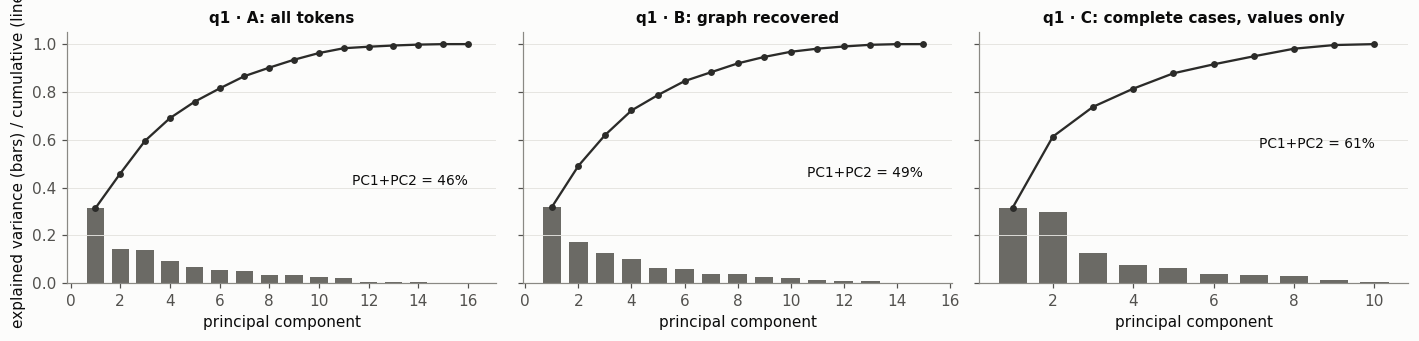

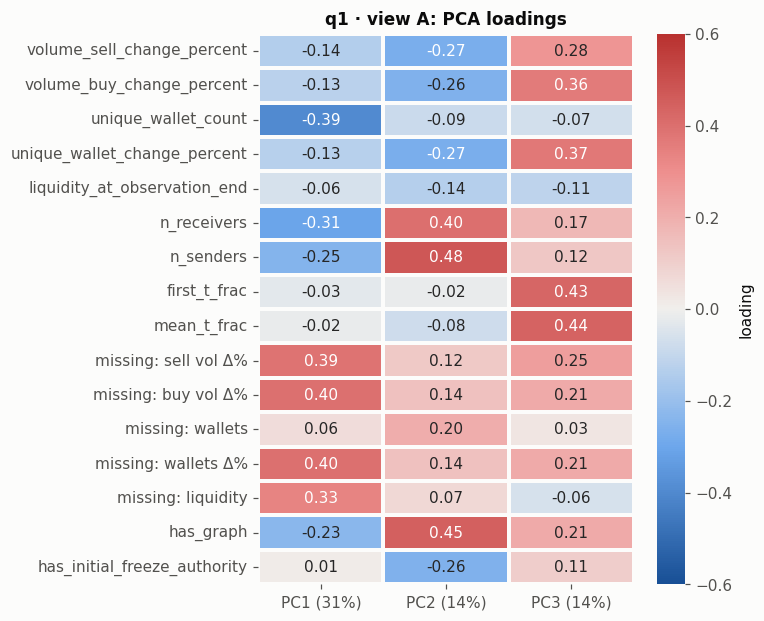

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, v in zip(axes, VIEWS):
    Z, cols, _ = mats[('q1', v)]
    evr = PCA().fit(Z).explained_variance_ratio_
    k = np.arange(1, len(evr) + 1)
    ax.bar(k, evr, color=NEUTRAL, width=0.7)
    ax.plot(k, np.cumsum(evr), 'o-', color='#2b2b29', ms=3.5, lw=1.5)
    ax.text(len(evr), np.cumsum(evr)[1], f'PC1+PC2 = {np.cumsum(evr)[1]:.0%}', ha='right', va='top',
            fontsize=9)
    ax.set_title(f'q1 · {v}', fontsize=10)
    ax.set_xlabel('principal component')
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('explained variance (bars) / cumulative (line)')
fig.tight_layout()
savefig(fig, '07_pca_scree_q1')
plt.show()

Z, cols, _ = mats[('q1', 'A: all tokens')]
pca_a = PCA(3, random_state=SEED).fit(Z)
loadings = pd.DataFrame(pca_a.components_.T, index=cols,
                        columns=[f'PC{i + 1} ({r:.0%})' for i, r in enumerate(pca_a.explained_variance_ratio_)])
fig, ax = plt.subplots(figsize=(5.5, 6.5))
sns.heatmap(loadings, cmap=DIVERGING, center=0, vmin=-0.6, vmax=0.6, annot=True, fmt='.2f',
            linewidths=1.5, linecolor='#fcfcfb', cbar_kws={'label': 'loading'}, ax=ax)
ax.set_title('q1 · view A: PCA loadings')
ax.grid(False)
savefig(fig, '07_pca_loadings_q1_viewA')
plt.show()

## 7.2 PCA, t-SNE, and UMAP Coloured by Label (q1)

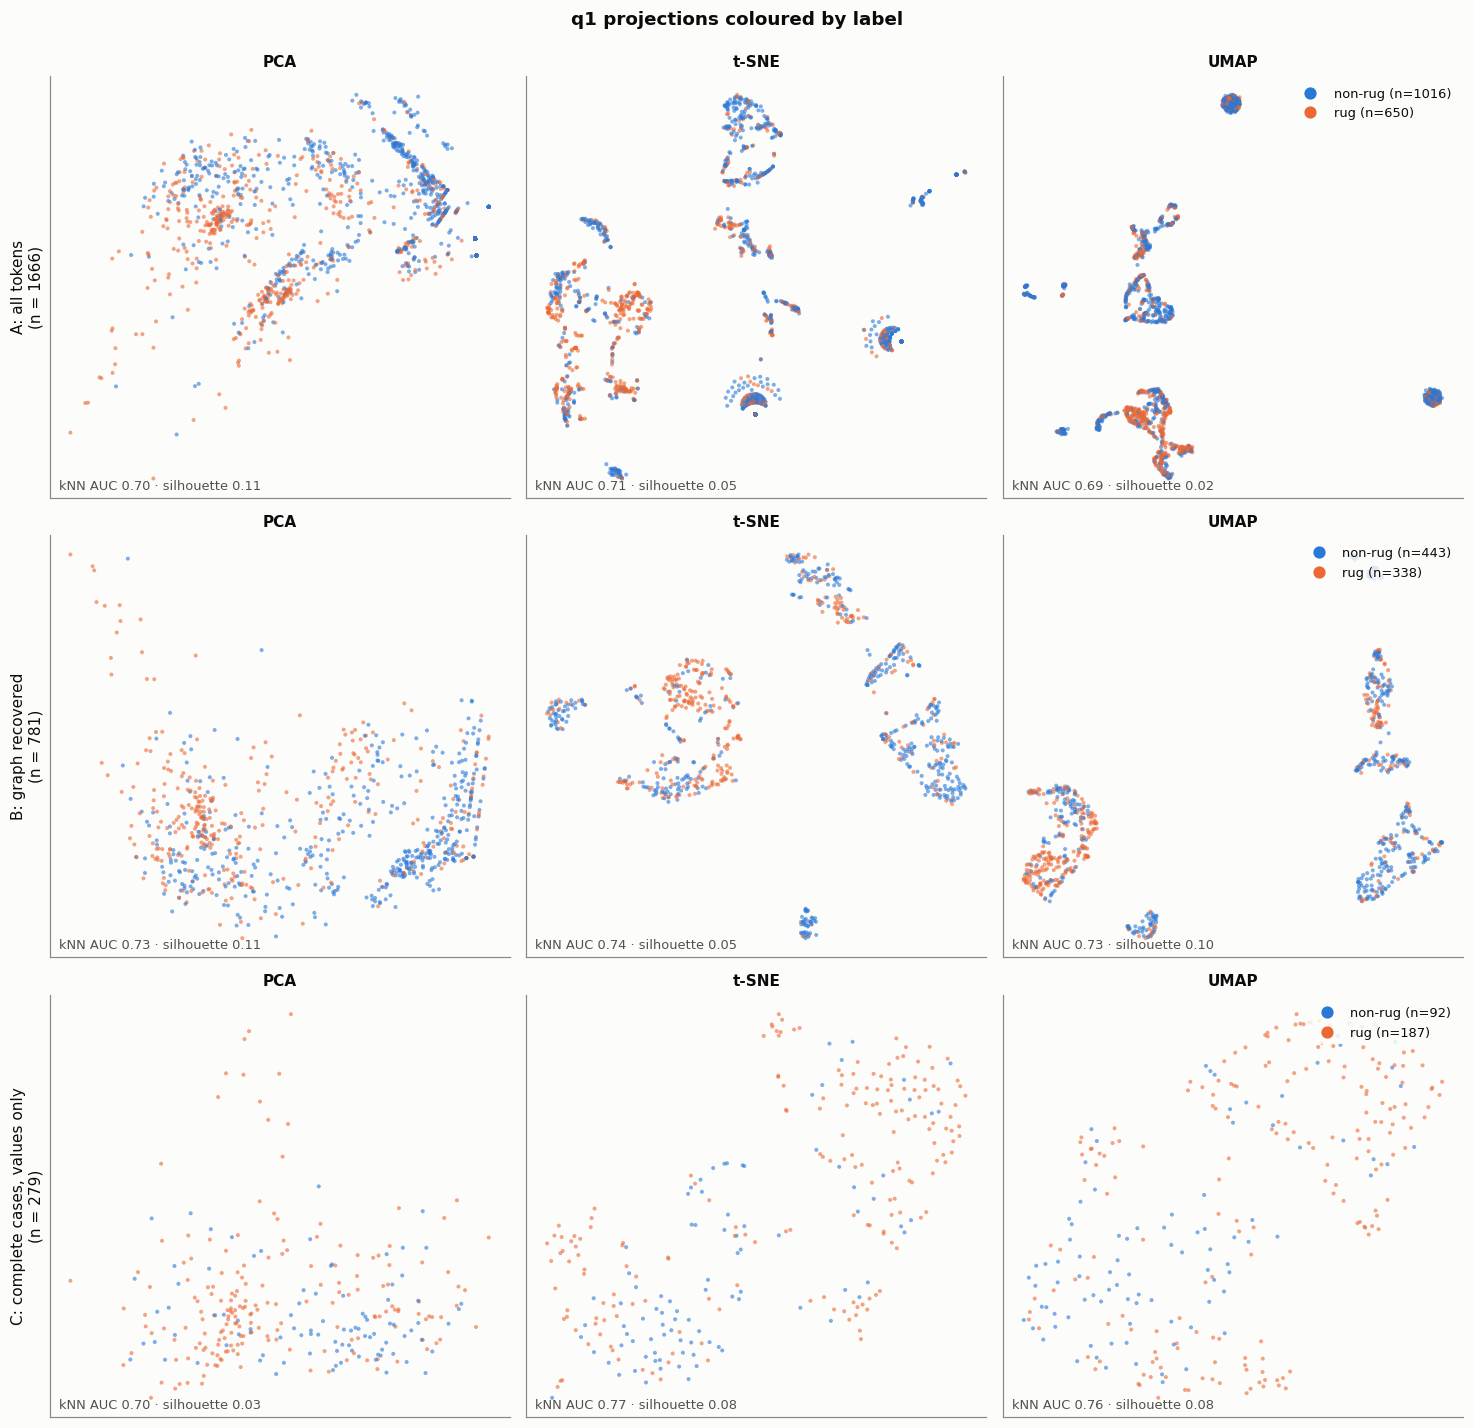

In [ ]:
def scatter_classes(ax, E, y, s=7):
    order = np.random.default_rng(SEED).permutation(len(y))   # random draw order: no class hidden on top
    ax.scatter(E[order, 0], E[order, 1], s=s, c=[CLASS_COLORS[k] for k in y[order]], alpha=0.6,
               linewidths=0, rasterized=True)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

def sep_label(q, v, m):
    r = separability.query('window == @q and view == @v and space == @m').iloc[0]
    return f'kNN AUC {r["kNN AUC"]:.2f} · silhouette {r["silhouette"]:.2f}'

fig, axes = plt.subplots(3, 3, figsize=(13.5, 13))
for i, v in enumerate(VIEWS):
    _, _, d = mats[('q1', v)]
    y = d['rug_pull_label'].to_numpy()
    for j, m in enumerate(METHODS):
        ax = axes[i, j]
        scatter_classes(ax, emb[('q1', v, m)], y)
        ax.set_title(f'{m}', fontsize=10)
        ax.text(0.02, 0.02, sep_label('q1', v, m), transform=ax.transAxes, fontsize=8.5, color='#52514e')
        if j == 0:
            ax.set_ylabel(f'{v}\n(n = {len(y)})', fontsize=10)
    axes[i, 2].legend(handles=class_handles(y), loc='upper right', fontsize=8.5,
                      bbox_to_anchor=(1.0, 1.0), framealpha=0.85, frameon=True, edgecolor='none')
fig.suptitle('q1 projections coloured by label', y=0.995, fontsize=12, fontweight='semibold')
fig.tight_layout()
savefig(fig, '07_projections_by_label_q1')
plt.show()

## 7.3 What Drives the Structure? Same Embeddings Coloured by Observed-Block Count and Creation Time

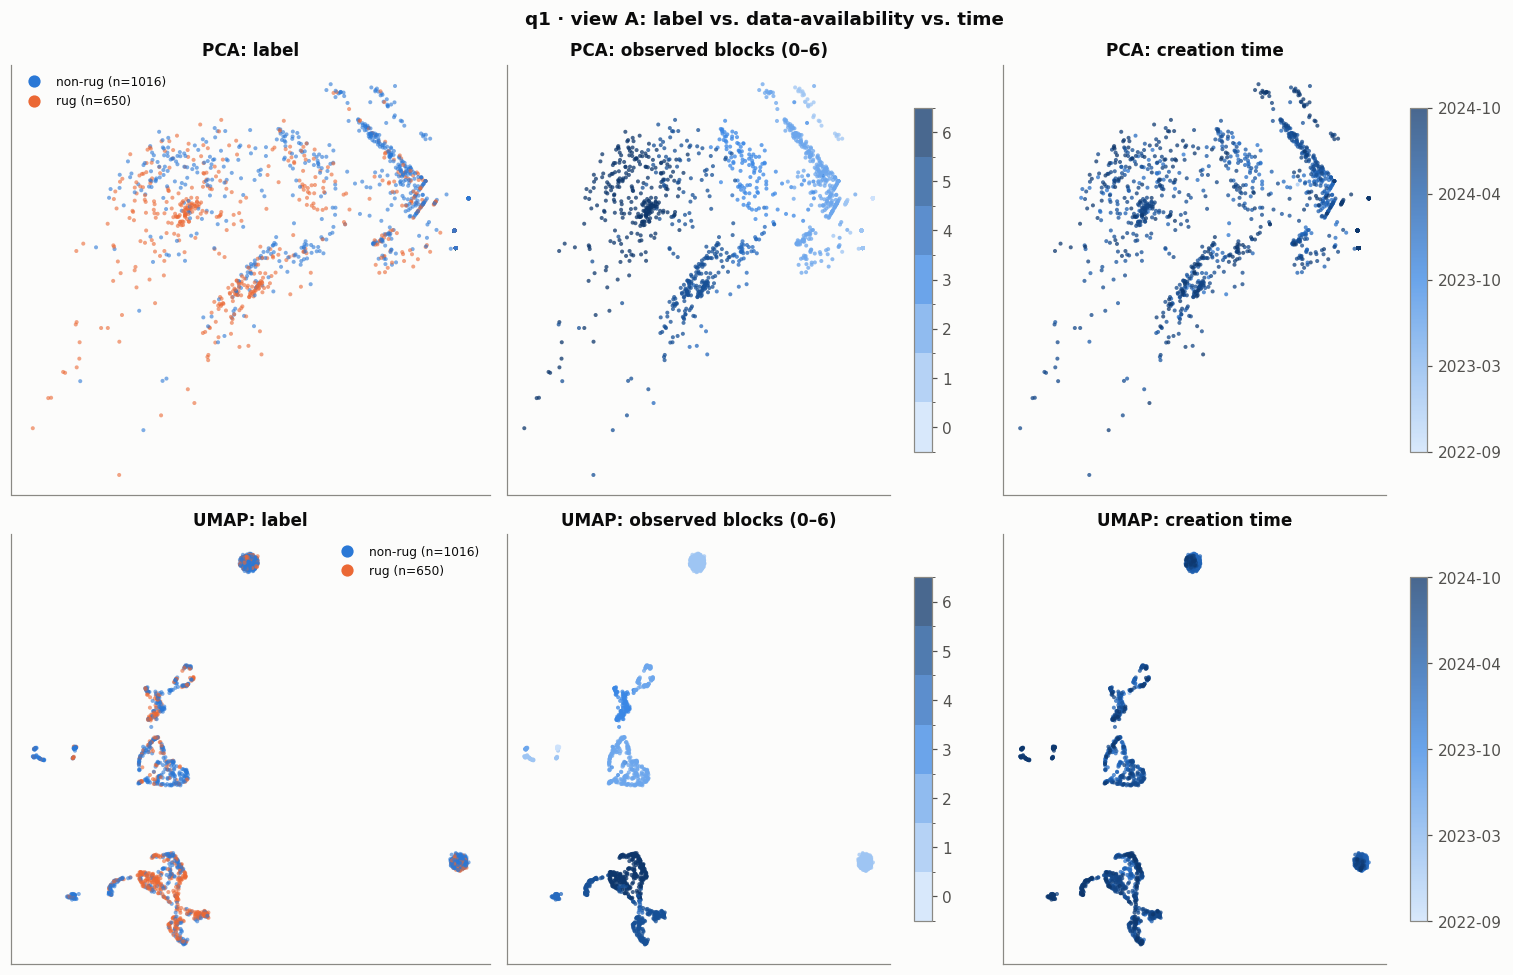

In [ ]:
_, _, dA = mats[('q1', 'A: all tokens')]
yA = dA['rug_pull_label'].to_numpy()
obs_cmap = LinearSegmentedColormap.from_list('obs', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
obs_norm = BoundaryNorm(np.arange(-0.5, 7.5), obs_cmap.N)
t_days = (dA['creation_utc'] - dA['creation_utc'].min()).dt.days.to_numpy()

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for i, m in enumerate(['PCA', 'UMAP']):
    E = emb[('q1', 'A: all tokens', m)]
    scatter_classes(axes[i, 0], E, yA)
    axes[i, 0].set_title(f'{m}: label')
    axes[i, 0].legend(handles=class_handles(yA), loc='best', fontsize=8)
    sc = axes[i, 1].scatter(E[:, 0], E[:, 1], s=7, c=dA['n_observed'], cmap=obs_cmap, norm=obs_norm,
                            alpha=0.75, linewidths=0, rasterized=True)
    axes[i, 1].set_title(f'{m}: observed blocks (0–6)')
    fig.colorbar(sc, ax=axes[i, 1], ticks=range(7), shrink=0.8)
    sc = axes[i, 2].scatter(E[:, 0], E[:, 1], s=7, c=t_days, cmap=SEQUENTIAL, alpha=0.75, linewidths=0,
                            rasterized=True)
    axes[i, 2].set_title(f'{m}: creation time')
    cb = fig.colorbar(sc, ax=axes[i, 2], shrink=0.8)
    ticks = np.linspace(t_days.min(), t_days.max(), 5)
    cb.set_ticks(ticks, labels=[(dA['creation_utc'].min() + pd.Timedelta(days=int(t))).strftime('%Y-%m')
                                for t in ticks])
    for ax in axes[i, 1:]:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle('q1 · view A: label vs. data-availability vs. time', fontsize=12, fontweight='semibold')
fig.tight_layout()
savefig(fig, '07_structure_drivers_q1')
plt.show()

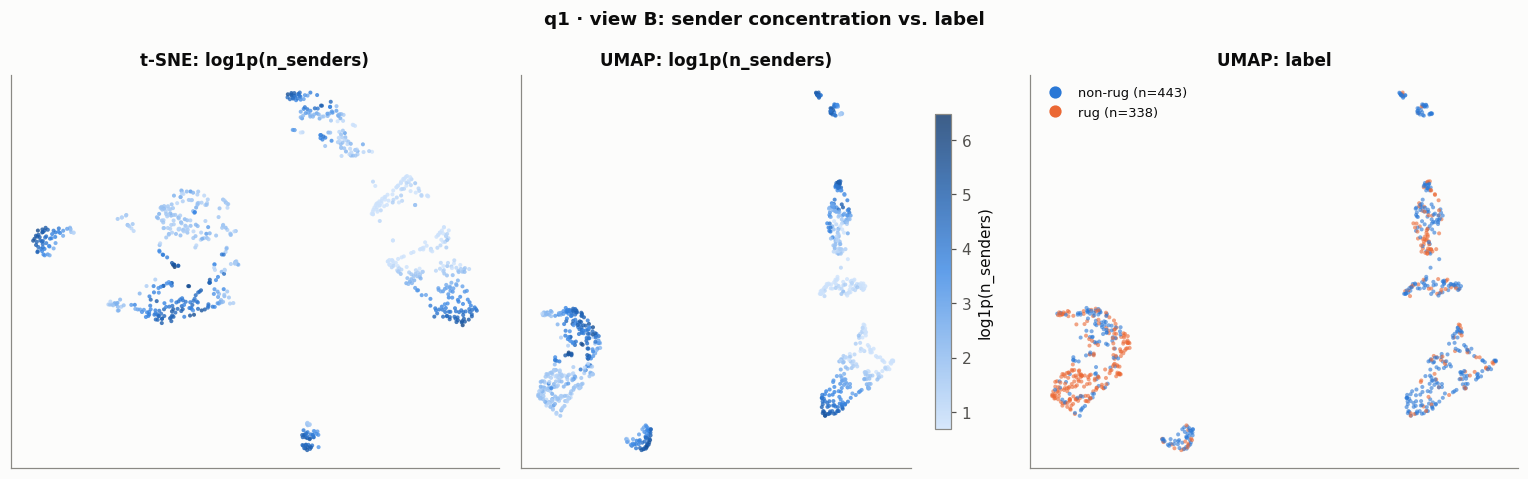

q1 view B rug rate: n_senders <= median (8): 52.2%, above median: 33.4%


In [ ]:
# View B: is the rug-rich region the low-sender (star-shaped) region?
_, _, dB = mats[('q1', 'B: graph recovered')]
yB = dB['rug_pull_label'].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, m in zip(axes[:2], ['t-SNE', 'UMAP']):
    E = emb[('q1', 'B: graph recovered', m)]
    sc = ax.scatter(E[:, 0], E[:, 1], s=7, c=np.log1p(dB['n_senders']), cmap=SEQUENTIAL, alpha=0.8,
                    linewidths=0, rasterized=True)
    ax.set_title(f'{m}: log1p(n_senders)')
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(sc, ax=axes[1], shrink=0.8, label='log1p(n_senders)')
scatter_classes(axes[2], emb[('q1', 'B: graph recovered', 'UMAP')], yB)
axes[2].set_title('UMAP: label')
axes[2].legend(handles=class_handles(yB), loc='best', fontsize=8.5)
fig.suptitle('q1 · view B: sender concentration vs. label', fontsize=12, fontweight='semibold')
fig.tight_layout()
savefig(fig, '07_viewB_senders_q1')
plt.show()

few = dB['n_senders'] <= dB['n_senders'].median()
print(f"q1 view B rug rate: n_senders <= median ({dB['n_senders'].median():.0f}): {yB[few].mean():.1%}, "
      f"above median: {yB[~few].mean():.1%}")

## 7.4 Stability Across Observation Windows (UMAP)

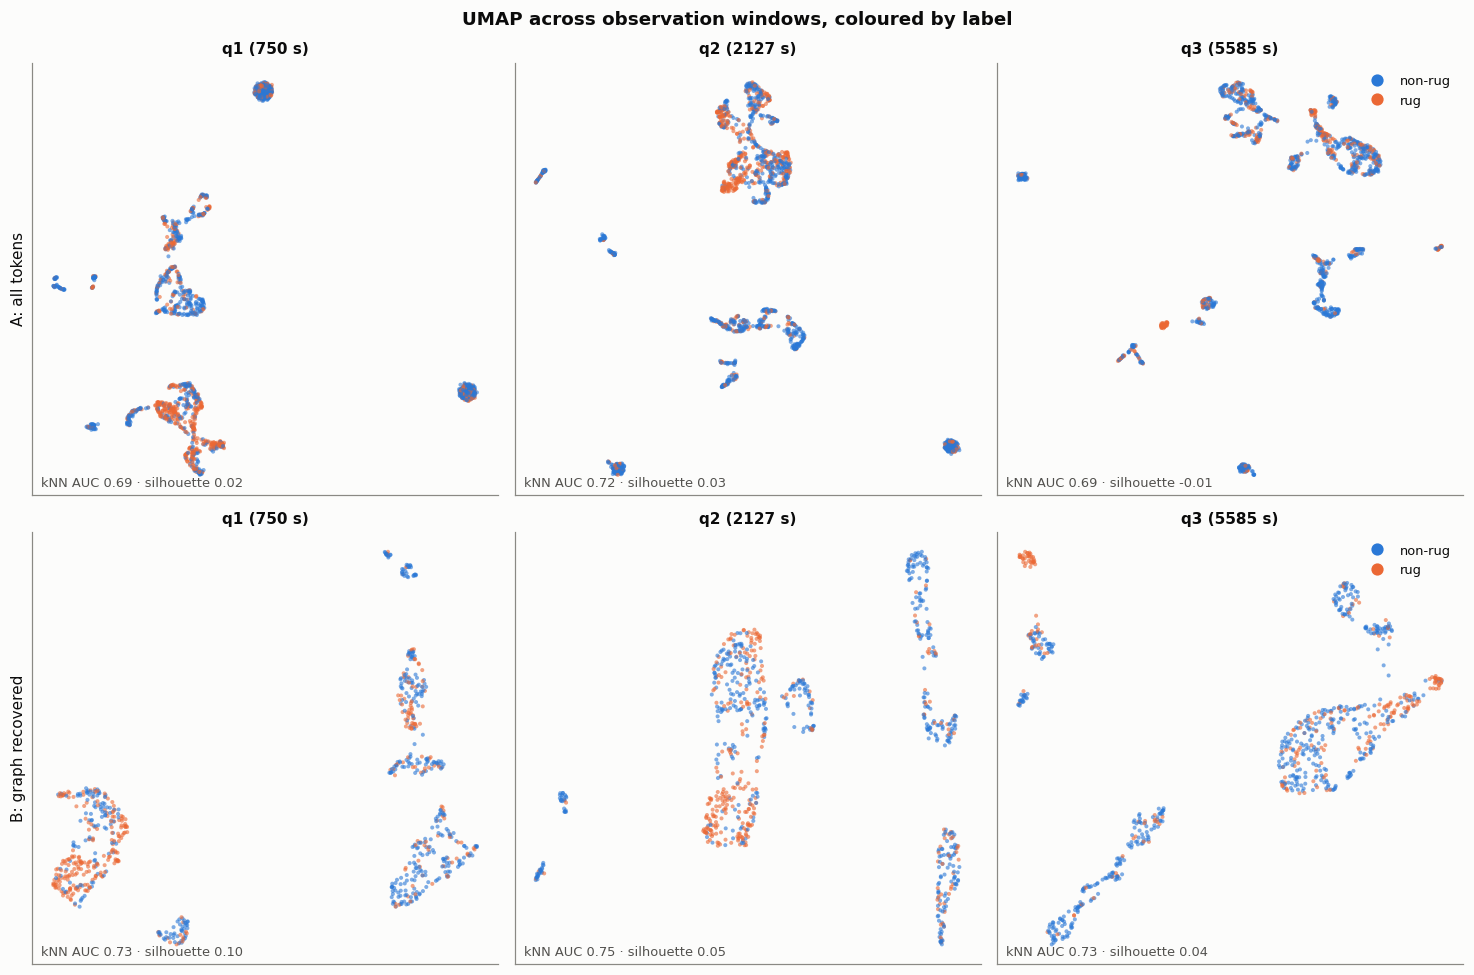

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 9))
for i, v in enumerate(['A: all tokens', 'B: graph recovered']):
    for j, q in enumerate(EXPERIMENTS):
        _, _, d = mats[(q, v)]
        y = d['rug_pull_label'].to_numpy()
        scatter_classes(axes[i, j], emb[(q, v, 'UMAP')], y)
        axes[i, j].set_title(f'{q} ({WINDOW_SECONDS[q]} s)', fontsize=10)
        axes[i, j].text(0.02, 0.02, sep_label(q, v, 'UMAP'), transform=axes[i, j].transAxes,
                        fontsize=8.5, color='#52514e')
        if j == 0:
            axes[i, j].set_ylabel(v, fontsize=10)
    axes[i, 2].legend(handles=class_handles(), loc='upper right', fontsize=8.5)
fig.suptitle('UMAP across observation windows, coloured by label', fontsize=12, fontweight='semibold')
fig.tight_layout()
savefig(fig, '07_umap_across_windows')
plt.show()

## 7.5 Quantified Separability

In [ ]:
sep_pivot = separability.pivot_table(index=['view', 'space'], columns='window',
                                     values=['kNN AUC', 'silhouette'])
sep_pivot = sep_pivot.reindex([(v, s) for v in VIEWS for s in ['full'] + METHODS])
(sep_pivot.style.format('{:.3f}')
 .background_gradient(cmap=SEQUENTIAL, subset=['kNN AUC'], vmin=0.5, vmax=0.8)
 .background_gradient(cmap=DIVERGING, subset=['silhouette'], vmin=-0.2, vmax=0.2))

## 7.6 Multivariate Anomalies

q1 view B: 39 anomalies of 781; rug rate among anomalies 46.2% vs 43.1% elsewhere


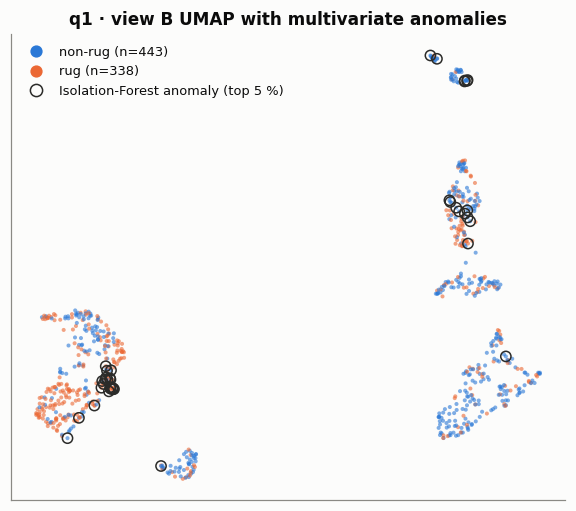

,volume_sell_change_percent,volume_buy_change_percent,unique_wallet_count,unique_wallet_change_percent,liquidity_at_observation_end,n_receivers,n_senders,first_t_frac,mean_t_frac,has_initial_freeze_authority,rug_pull_label,score
506,NaN,1.65e+07,86,"1,950",1.722e+05,885,14,0.468,0.9378,True,0,0.6471
510,NaN,2.506e+06,55,716.7,2.483e+05,"2,399",29,0.4627,0.8507,True,1,0.6429
649,NaN,1.862e+05,10,300,"8,860",11,2,0.4573,0.6978,True,0,0.6254
70,NaN,1.602e+04,10,800,NaN,11,2,0.32,0.6239,False,1,0.6152
487,1.531e+05,2.199e+05,289,"4,617",6.93e+04,290,3,0.164,0.7593,True,1,0.6104
445,NaN,5.283e+04,541,2.69e+04,3.447e+04,619,80,0,0.604,False,1,0.6095
738,NaN,NaN,1,NaN,10,1,1,0.9253,0.956,True,0,0.6072
576,NaN,NaN,NaN,NaN,0,27,19,0,0.5582,False,0,0.6036
668,NaN,NaN,0,NaN,60,1,1,0.9453,0.9453,True,0,0.6008
328,1e+05,-99.98,20,-76.47,NaN,96,2,0.464,0.7289,True,1,0.5981


In [ ]:
# Isolation Forest on view B (graph-recovered tokens, all values present or imputed with indicators).
Z, cols, dB = mats[('q1', 'B: graph recovered')]
iso = IsolationForest(n_estimators=500, contamination=0.05, random_state=SEED).fit(Z)
anomalous = iso.predict(Z) == -1
yB = dB['rug_pull_label'].to_numpy()
print(f'q1 view B: {anomalous.sum()} anomalies of {len(yB)}; rug rate among anomalies '
      f'{yB[anomalous].mean():.1%} vs {yB[~anomalous].mean():.1%} elsewhere')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
E = emb[('q1', 'B: graph recovered', 'UMAP')]
scatter_classes(ax, E, yB)
ax.scatter(E[anomalous, 0], E[anomalous, 1], s=45, facecolors='none', edgecolors='#2b2b29', linewidths=1)
ax.legend(handles=class_handles(yB) + [Line2D([], [], marker='o', ls='', mfc='none', mec='#2b2b29',
                                              markersize=8, label='Isolation-Forest anomaly (top 5 %)')],
          loc='best', fontsize=8.5)
ax.set_title('q1 · view B UMAP with multivariate anomalies')
savefig(fig, '07_anomalies_q1_viewB')
plt.show()

show = DR_NODE + DR_GRAPH + ['has_initial_freeze_authority', 'rug_pull_label']
dB.loc[anomalous, show].assign(score=-iso.score_samples(Z)[anomalous]).sort_values('score', ascending=False).head(12)

**<span style="color:red">Observation:</span>** **What the projections show.**<br>* **View A (all tokens).** The embeddings are dominated by data availability, not by the label. PCA's first component (31 % of variance) contrasts the missing indicators with activity size (wallet count, receivers, senders). The UMAP islands line up with the observed-block count (Section 7.3, middle column). Within the "fully observed" island rugs concentrate in a lobe, and the sparse islands are mostly non-rug.<br>* **Creation time** shows no separate cluster (right column): the structure is not an artefact of collection period.<br>* **View B (graph recovered).** UMAP forms two large islands. In one of them, the low-sender lobe (star-shaped graphs) is clearly rug-rich; the other island is mostly non-rug at every sender count (Section 7.4 figure). Overall, view-B tokens at or below the median sender count (8) are 52 % rugs, against 33 % above it. This is the clearest visual separation.<br>* **View C (complete cases, values only).** It has no missingness information and still reaches kNN AUC 0.76–0.77 in q1/q2. The *values* separate the classes on their own once data exists; separation is not only a missingness artefact.<br><br>**Quantified.** Neighbourhood purity (kNN AUC) is 0.69–0.77 in every view and window, and silhouettes are ≈ 0–0.1. The classes form **overlapping, partially enriched regions, not separable clusters**. The 2-D embeddings keep almost all the neighbourhood signal of the full space (e.g. q1 view B: 0.75 full vs 0.73 UMAP), so the useful structure is low-dimensional. Separability is similar across q1/q2/q3, except that q3 is weaker on complete cases (view C: 0.70 vs 0.76).<br><br>**Anomalies.** Isolation Forest's top 5 % (q1 view B) are tokens with extreme volume or wallet growth, or degenerate 1–2 node graphs. Their rug rate (46 %) barely differs from the rest (43 %), so multivariate outliers are not a separate rug signature and need no special handling.<br><br>**Method note.** t-SNE/UMAP inter-cluster distances and cluster sizes are not meaningful. Only neighbourhood membership is, which is why kNN AUC is reported. A third embedding dimension was not used: two dimensions already preserve the neighbourhood signal.

## 7.7 Chronological Split: Where Do Later Tokens Fall?

The chronological split from `artifacts/splits/` orders tokens by creation time:
**train** = 70 % oldest (to 2024-07-25), **validation** = next 15 % (2024-07-26 to 2024-09-07),
**test** = newest 15 % (2024-09-08 onward). Nine tokens straddling a boundary are embargoed and left
out here. The assignment is per token, so it is identical across q1/q2/q3.

Everything is **fitted on train only**: imputation medians, scaling, PCA and UMAP. Validation and
test tokens are projected through these fitted transforms, as a deployed model would see them.
In the validation and test panels, grey points are the training tokens and coloured points are the
split's own tokens.

**Transfer kNN AUC**: each validation/test token is scored by the rug share among its 15 nearest
*training* tokens in the shown space. AUC against the true label tells whether the neighbourhood
structure learned on older tokens still separates newer ones. For the train panel, the same score
excludes each point itself.

In [ ]:
chrono = pd.read_parquet('./artifacts/splits/chronological_split_manifest.parquet',
                         columns=['token_mint', 'split']).rename(columns={'split': 'chrono_split'})
SPLITS = ['train', 'validation', 'test']
SPLIT_GRAY = '#cfcec8'

def chrono_frame(q):
    d = raw[q].merge(chrono, on='token_mint', how='left', validate='one_to_one')
    assert d['chrono_split'].notna().all()
    return d[d['chrono_split'] != 'embargo'].reset_index(drop=True)

def matrix_fit_on_train(d, is_train, numeric=DR_NODE + DR_GRAPH, booleans=DR_BOOL):
    """Same encoding as view A, but medians and scaling come from training rows only."""
    X = pd.DataFrame({c: tf(d, c) for c in numeric}, index=d.index)
    for c in numeric:
        if c in NODE_NUM:
            X[f'missing: {SHORT[c]}'] = X[c].isna().astype(float)
    X['has_graph'] = d['has_graph'].astype(float)
    for c in numeric:
        if c in GRAPH_COUNTS:
            X[c] = X[c].fillna(0.0)
    X = X.fillna(X[is_train].median())
    for b in booleans:
        X[b] = d[b].astype(float)
    return StandardScaler().fit(X[is_train]).transform(X)

def transfer_knn_auc(E_ref, y_ref, E_eval, y_eval, k=15, exclude_self=False):
    nn = NearestNeighbors(n_neighbors=k + exclude_self).fit(E_ref)
    idx = nn.kneighbors(E_eval, return_distance=False)[:, int(exclude_self):]
    return roc_auc_score(y_eval, y_ref[idx].mean(axis=1))

chrono_emb, chrono_rows = {}, []
for q in EXPERIMENTS:
    d = chrono_frame(q)
    is_train = (d['chrono_split'] == 'train').to_numpy()
    y = d['rug_pull_label'].to_numpy()
    Z = matrix_fit_on_train(d, is_train)
    spaces = {
        'full': Z,
        'PCA': PCA(2, random_state=SEED).fit(Z[is_train]).transform(Z),
        'UMAP': umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit(Z[is_train]).transform(Z),
    }
    chrono_emb[q] = (d, spaces)
    for space, E in spaces.items():
        for sp in SPLITS:
            m = (d['chrono_split'] == sp).to_numpy()
            chrono_rows.append({
                'window': q, 'space': space, 'split': sp, 'tokens': int(m.sum()), 'rug rate': y[m].mean(),
                'transfer kNN AUC': transfer_knn_auc(E[is_train], y[is_train], E[m], y[m],
                                                     exclude_self=(sp == 'train')),
            })
chrono_sep = pd.DataFrame(chrono_rows)
chrono_sep.pivot_table(index=['space', 'split'], columns='window',
                       values=['transfer kNN AUC', 'rug rate']).reindex(
    [(s, sp) for s in ['full', 'PCA', 'UMAP'] for sp in SPLITS])

rug rate               transfer kNN AUC              
window                 q1     q2     q3               q1     q2     q3
space split                                                           
full  train        0.3753 0.3416 0.2886           0.6747 0.7024 0.6916
      validation   0.5601 0.5281 0.4489           0.7738 0.8053 0.7964
      test         0.2925  0.276 0.2292           0.6648 0.6379 0.5872
PCA   train        0.3753 0.3416 0.2886           0.6833 0.7143 0.6592
      validation   0.5601 0.5281 0.4489           0.7397 0.7986 0.7102
      test         0.2925  0.276 0.2292           0.6358 0.6747 0.6196
UMAP  train        0.3753 0.3416 0.2886           0.6796  0.682 0.6906
      validation   0.5601 0.5281 0.4489           0.7654 0.7897 0.7742
      test         0.2925  0.276 0.2292           0.6454  0.669 0.5292

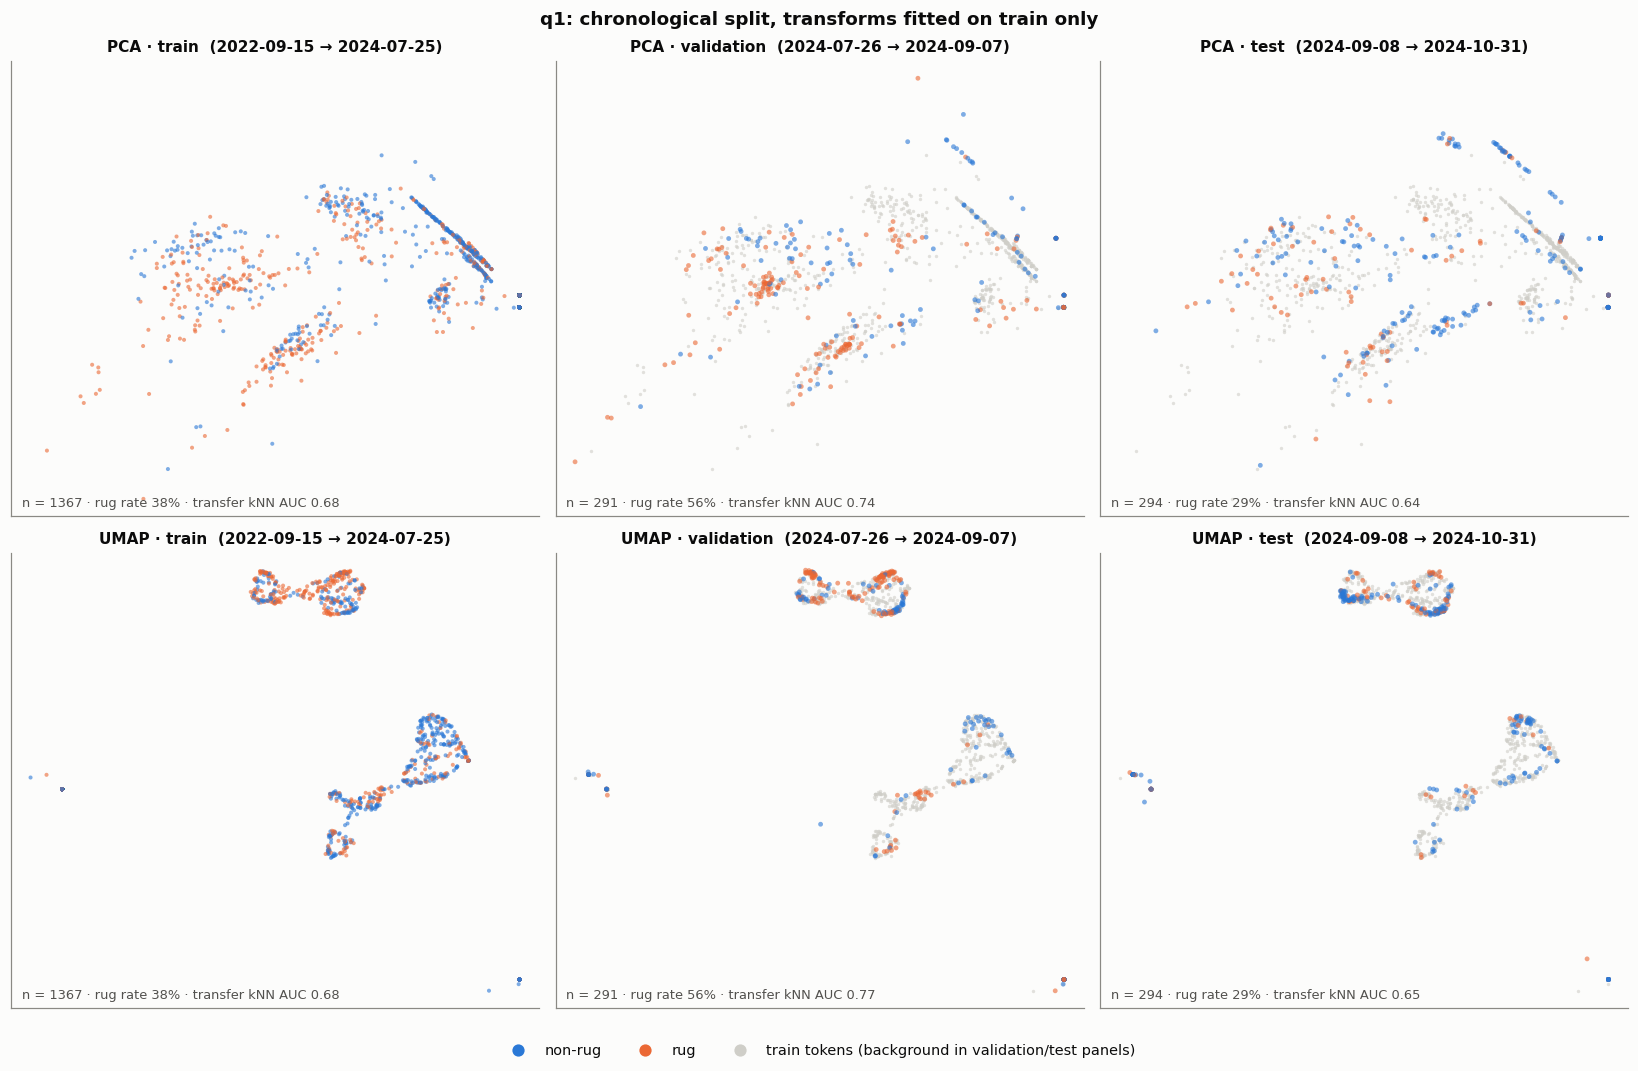

In [ ]:
def plot_chrono(q, spaces_to_plot=('PCA', 'UMAP')):
    d, spaces = chrono_emb[q]
    y = d['rug_pull_label'].to_numpy()
    split = d['chrono_split'].to_numpy()
    fig, axes = plt.subplots(len(spaces_to_plot), 3, figsize=(15, 4.9 * len(spaces_to_plot)),
                             squeeze=False)
    for i, space in enumerate(spaces_to_plot):
        E = spaces[space]
        tr = split == 'train'
        # identical limits in a row so the panels are directly comparable
        pad = 0.04 * (E.max(axis=0) - E.min(axis=0))
        lims = (E.min(axis=0) - pad, E.max(axis=0) + pad)
        for j, sp in enumerate(SPLITS):
            ax = axes[i, j]
            m = split == sp
            if sp != 'train':
                ax.scatter(E[tr, 0], E[tr, 1], s=5, color=SPLIT_GRAY, alpha=0.6, linewidths=0,
                           rasterized=True)
            scatter_classes(ax, E[m], y[m], s=10 if sp != 'train' else 7)
            ax.set_xlim(lims[0][0], lims[1][0])
            ax.set_ylim(lims[0][1], lims[1][1])
            r = chrono_sep.query('window == @q and space == @space and split == @sp').iloc[0]
            dates = d.loc[m, 'creation_utc']
            ax.set_title(f'{space} · {sp}  ({dates.min():%Y-%m-%d} → {dates.max():%Y-%m-%d})', fontsize=10)
            ax.text(0.02, 0.02,
                    f'n = {m.sum()} · rug rate {y[m].mean():.0%} · transfer kNN AUC {r["transfer kNN AUC"]:.2f}',
                    transform=ax.transAxes, fontsize=8.5, color='#52514e')
    handles = class_handles() + [Line2D([], [], marker='o', ls='', color=SPLIT_GRAY, markersize=7,
                                        label='train tokens (background in validation/test panels)')]
    fig.suptitle(f'{q}: chronological split, transforms fitted on train only',
                 fontsize=12, fontweight='semibold')
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=9.5)
    savefig(fig, f'07_chronological_split_{q}')
    plt.show()

plot_chrono('q1')

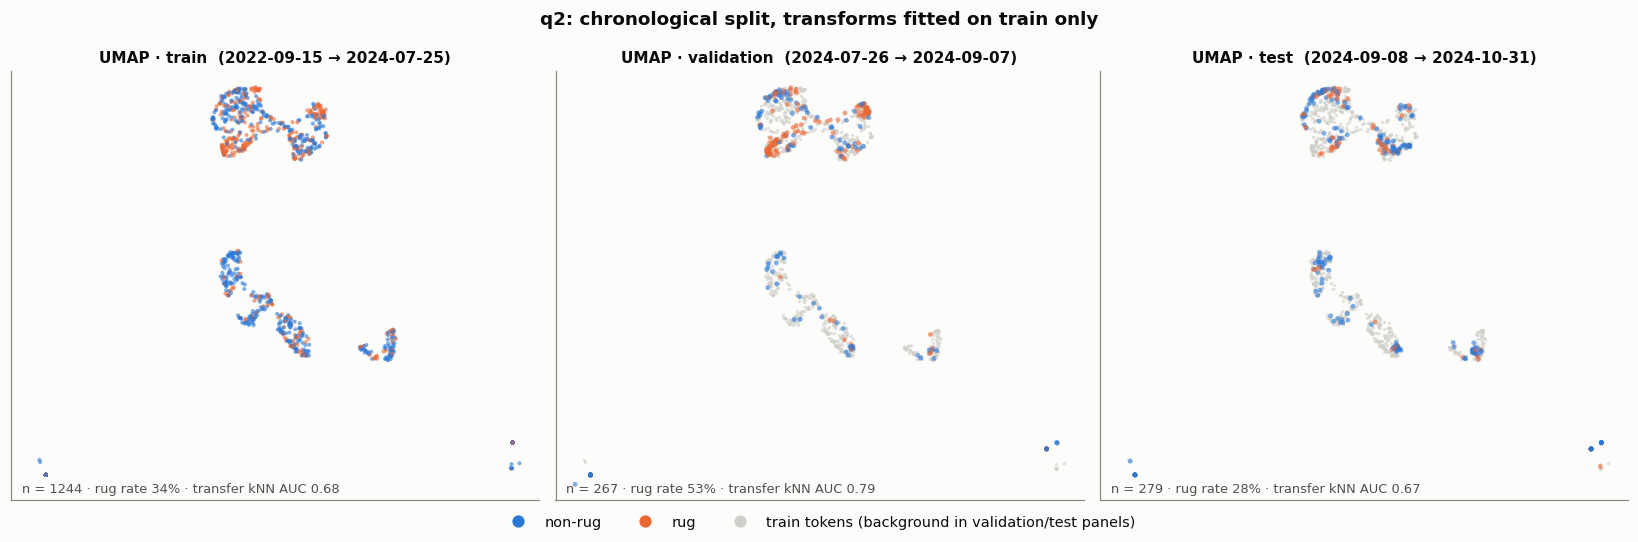

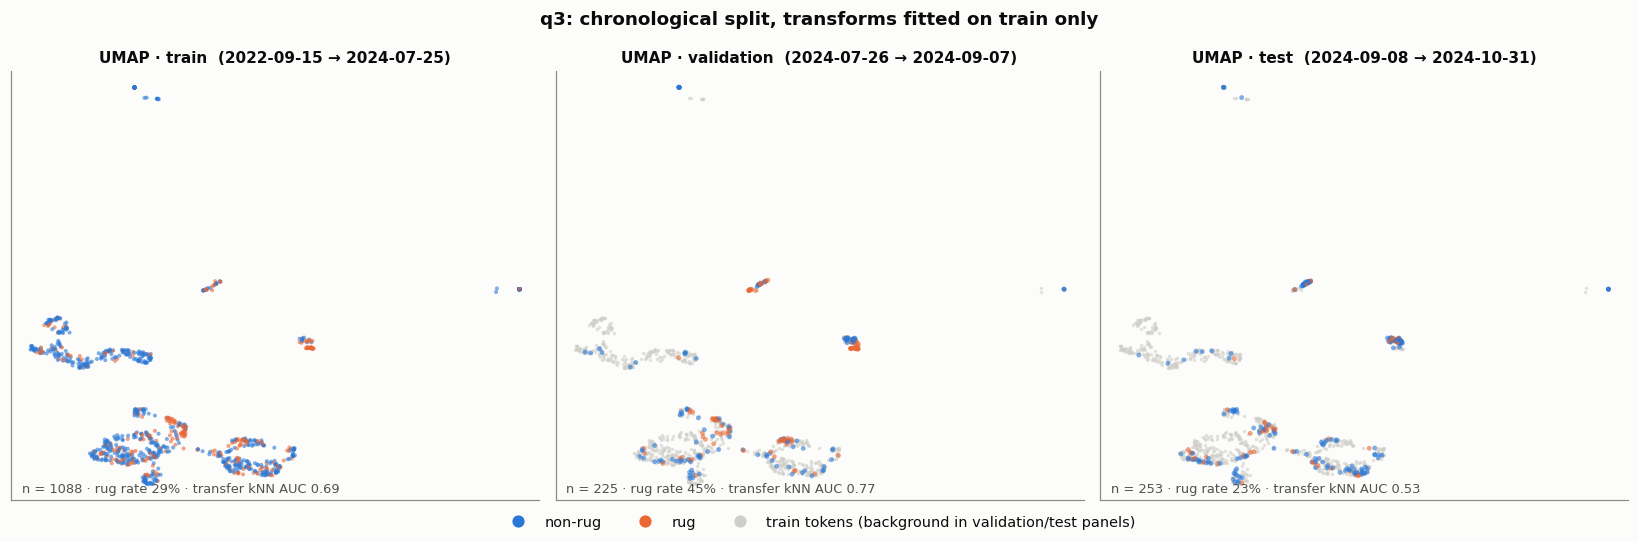

In [ ]:
# The same view for the longer windows (UMAP only).
for q in ['q2', 'q3']:
    plot_chrono(q, spaces_to_plot=('UMAP',))

**<span style="color:red">Observation:</span>** **The chronological split differs in label rate and in where tokens fall.**<br>* **Prevalence shifts sharply over time.** Rug rate is 38 % in train, 56 % in validation (late Jul to early Sep 2024) and 29 % in test (Sep to Oct 2024) for q1, with the same up-then-down pattern in q2/q3. A model whose threshold or calibration is chosen on validation will be badly calibrated on test.<br>* **Validation is easier than train; test is harder.** Training-neighbour kNN AUC in the full space is 0.77–0.81 on validation, 0.67–0.70 within train and only 0.59–0.66 on test. In q3 the UMAP transfer score on test falls to 0.53, close to chance.<br>* **Where the points land.** Validation tokens concentrate in the regions that were already rug-rich in training (q1 PCA upper-left cloud, the q1 UMAP top island), which is why they are easy. Test tokens largely avoid the oldest training regions (e.g. q3's left UMAP island is nearly empty). Some land beyond the training range (q1 PCA, upper right, mostly non-rug). In q3, the small right-hand island that is rug-heavy in validation is mostly non-rug in test, so the same feature profile carries a different label later on (concept drift, not only a change in which tokens appear).<br><br>**Implications.**<br>* Validation scores from this split will overstate test performance, so tune decision thresholds with that in mind; prevalence-robust metrics (ROC-AUC, PR-AUC relative to base rate) are safer.<br>* Comparing stratified-split and chronological-split results gives a direct measure of how much temporal drift costs.<br>* Models that rely on the "rug-rich regions" learned from 2024 H1 may not transfer to autumn 2024 tokens.

## 7.8 Stratified Split: Train-Fitted Projections for All Tokens and Graph-Bearing Tokens

This is the same construction as 7.7, applied to the **stratified random split** used for model
development (70/15/15 by token, stratified on the label, `artifacts_stratified/splits/`). Two populations:

* **all tokens**: view A encoding (values + missing indicators);
* **graph-bearing tokens**: view B (only tokens with at least one recovered transfer edge).

Imputation medians, scaling, PCA and UMAP are fitted on **train only**; validation and test tokens
are projected through them. Test rows are only projected, never fitted. Grey points in the
validation/test panels are the training tokens. **Transfer kNN AUC** is defined as in 7.7.

Because the stratified split draws all three partitions from the same time range and label mix,
validation and test should overlap the training cloud and transfer about as well as train itself.
This is the reference against which the chronological split in 7.7 can be judged.

In [ ]:
STRAT_POPULATIONS = {
    'all tokens': lambda d: np.ones(len(d), dtype=bool),
    'graph-bearing tokens': lambda d: d['has_graph'].to_numpy(),
}

strat_emb, strat_rows = {}, []
for q in EXPERIMENTS:
    for pop, rule in STRAT_POPULATIONS.items():
        d = raw[q][rule(raw[q])].reset_index(drop=True)
        is_train = (d['split'] == 'train').to_numpy()
        y = d['rug_pull_label'].to_numpy()
        Z = matrix_fit_on_train(d, is_train)
        spaces = {
            'full': Z,
            'PCA': PCA(2, random_state=SEED).fit(Z[is_train]).transform(Z),
            'UMAP': umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit(Z[is_train]).transform(Z),
        }
        strat_emb[(q, pop)] = (d, spaces)
        for space, E in spaces.items():
            for sp in SPLITS:
                m = (d['split'] == sp).to_numpy()
                strat_rows.append({
                    'window': q, 'population': pop, 'space': space, 'split': sp,
                    'tokens': int(m.sum()), 'rug rate': y[m].mean(),
                    'transfer kNN AUC': transfer_knn_auc(E[is_train], y[is_train], E[m], y[m],
                                                         exclude_self=(sp == 'train')),
                })
strat_sep = pd.DataFrame(strat_rows)
strat_sep.pivot_table(index=['population', 'space', 'split'], columns='window',
                      values=['transfer kNN AUC', 'rug rate'], sort=False).round(3)

transfer kNN AUC             rug rate            
window                                              q1    q2    q3       q1    q2    q3
population           space split                                                       
all tokens           full  train                 0.706 0.712 0.691     0.39 0.359 0.301
                           validation            0.692 0.714 0.733    0.391 0.359 0.321
                           test                  0.716 0.742 0.638     0.39 0.356 0.283
                     PCA   train                 0.709 0.714 0.661     0.39 0.359 0.301
                           validation            0.721 0.747 0.734    0.391 0.359 0.321
                           test                  0.704 0.755 0.632     0.39 0.356 0.283
                     UMAP  train                 0.696 0.703  0.68     0.39 0.359 0.301
                           validation            0.704 0.722 0.684    0.391 0.359 0.321
                           test                    0.7 0.738 0.662     0.39 0.356 0.283
graph-bearing tokens full  train                 0.733 0.739 0.742    0.436 0.389 0.311
                           validation            0.784 0.777 0.749     0.42 0.372 0.344
                           test                  0.809 0.777 0.728    0.462 0.424 0.325
                     PCA   train                 0.717 0.735 0.684    0.436 0.389 0.311
                           validation            0.744 0.771 0.677     0.42 0.372 0.344
                           test                  0.735 0.773  0.67    0.462 0.424 0.325
                     UMAP  train                 0.742 0.743 0.705    0.436 0.389 0.311
                           validation            0.791 0.744 0.712     0.42 0.372 0.344
                           test                  0.771 0.762 0.726    0.462 0.424 0.325

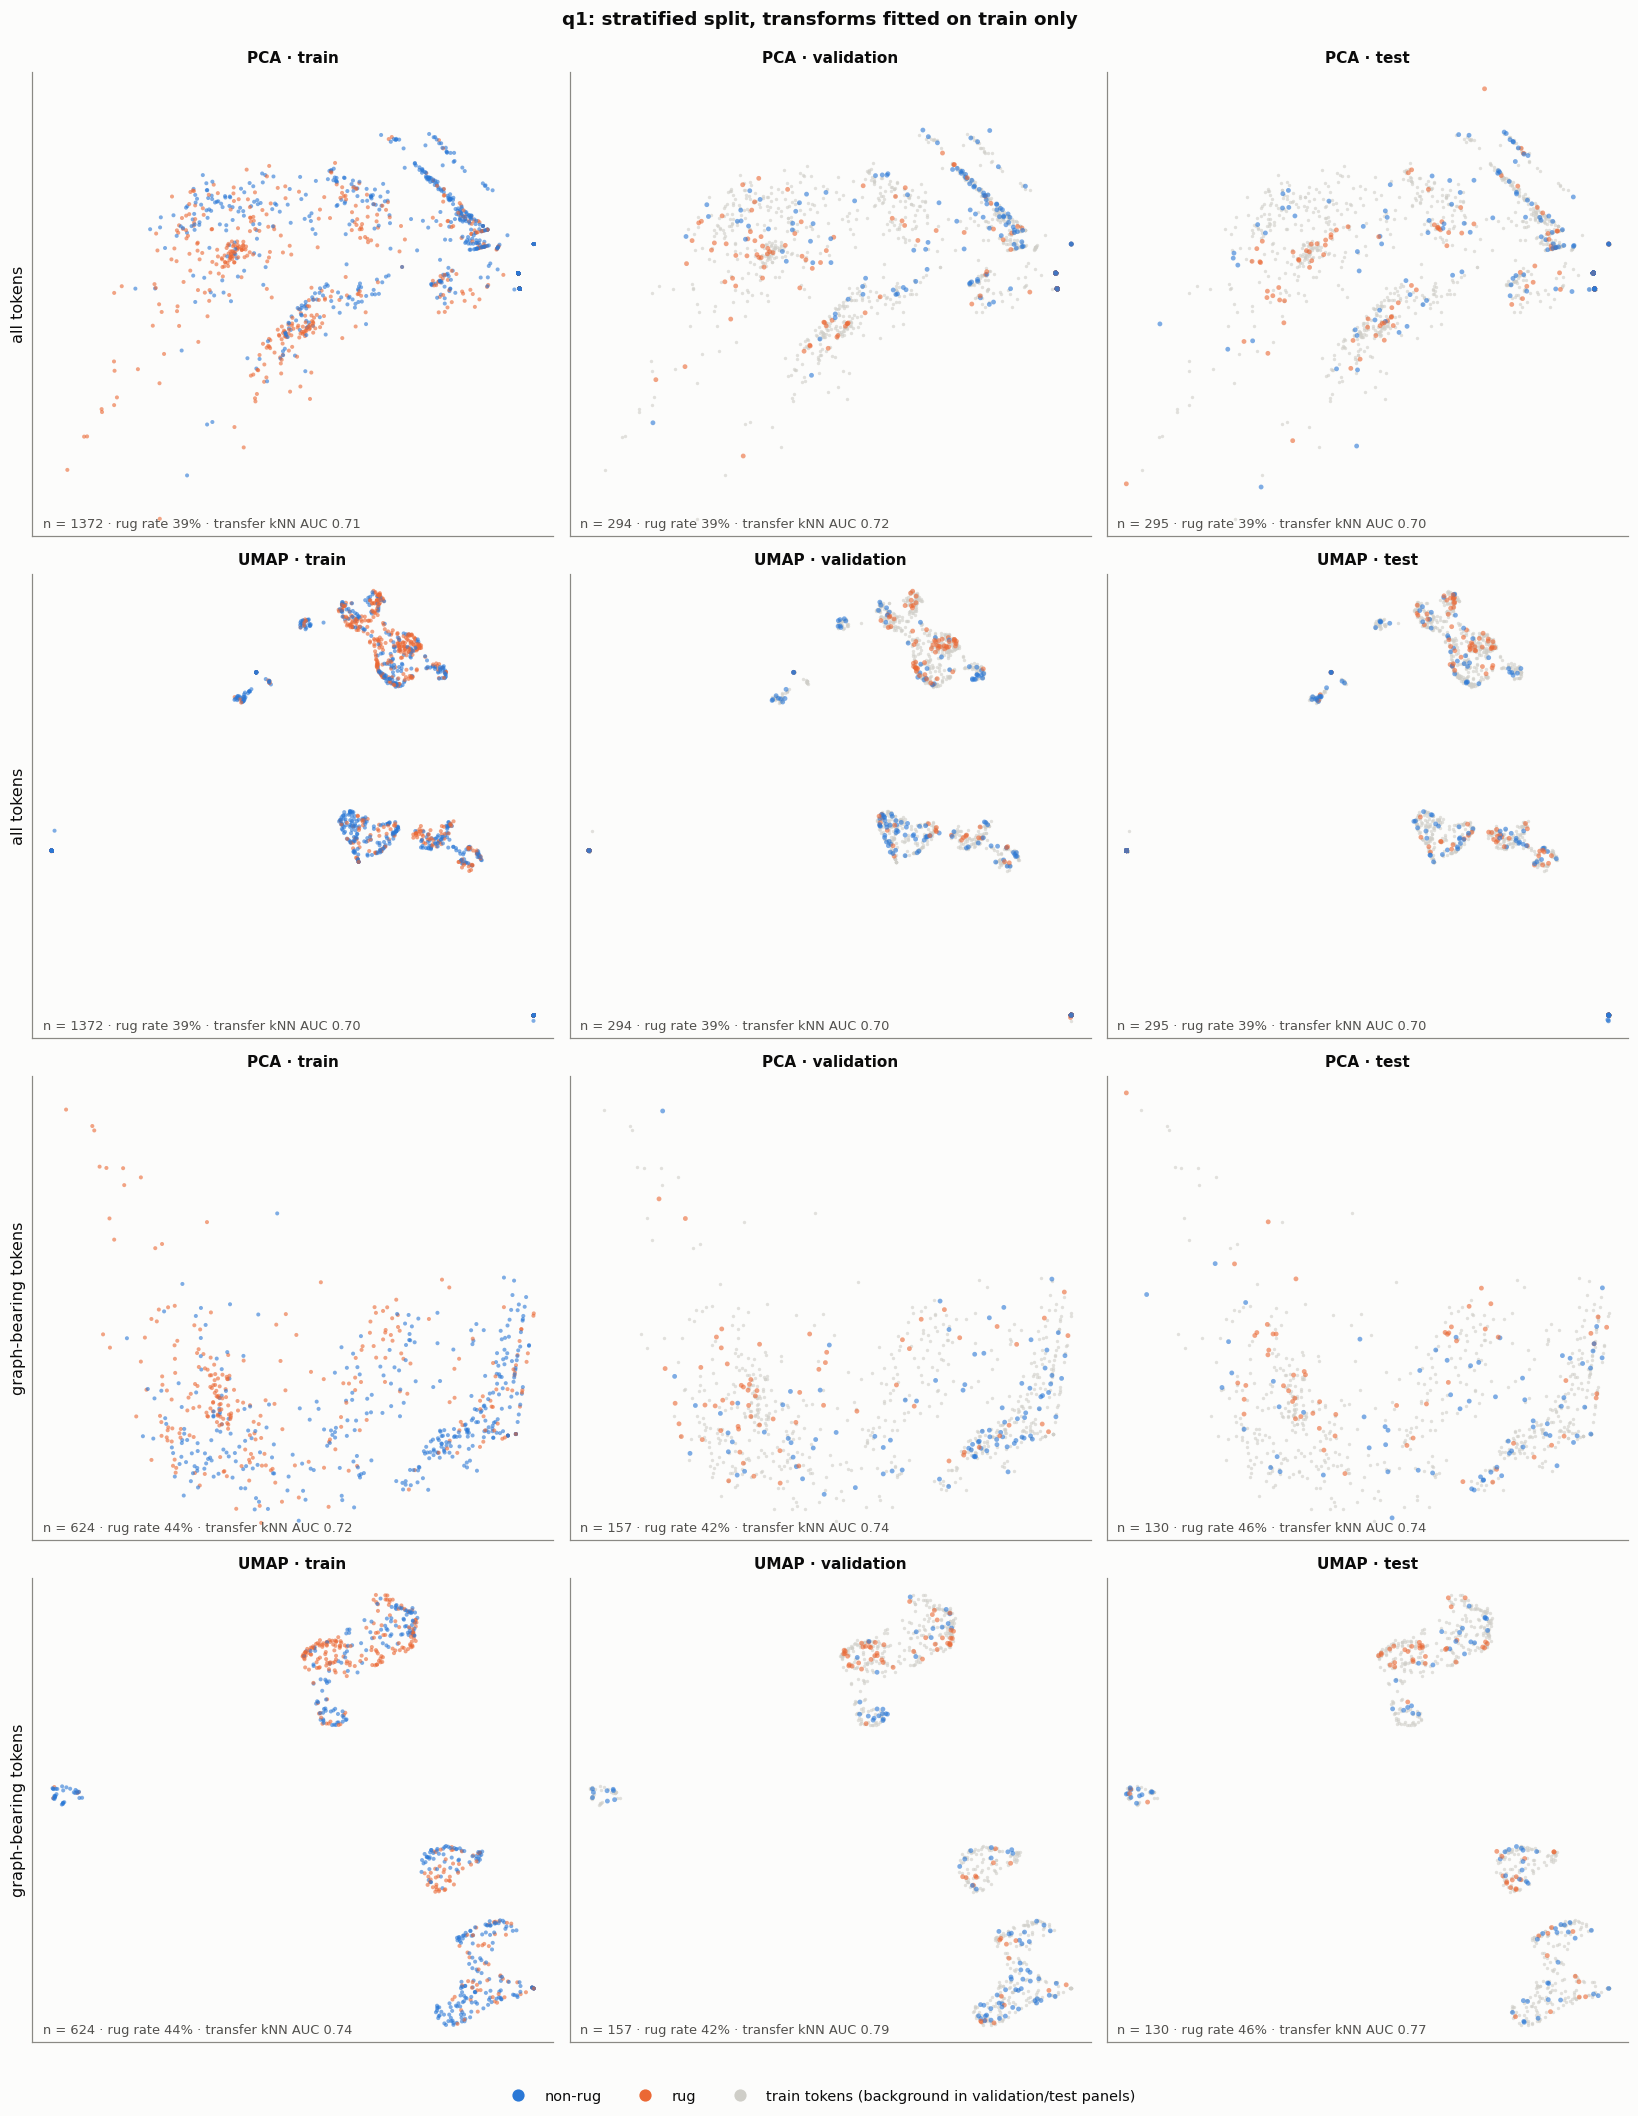

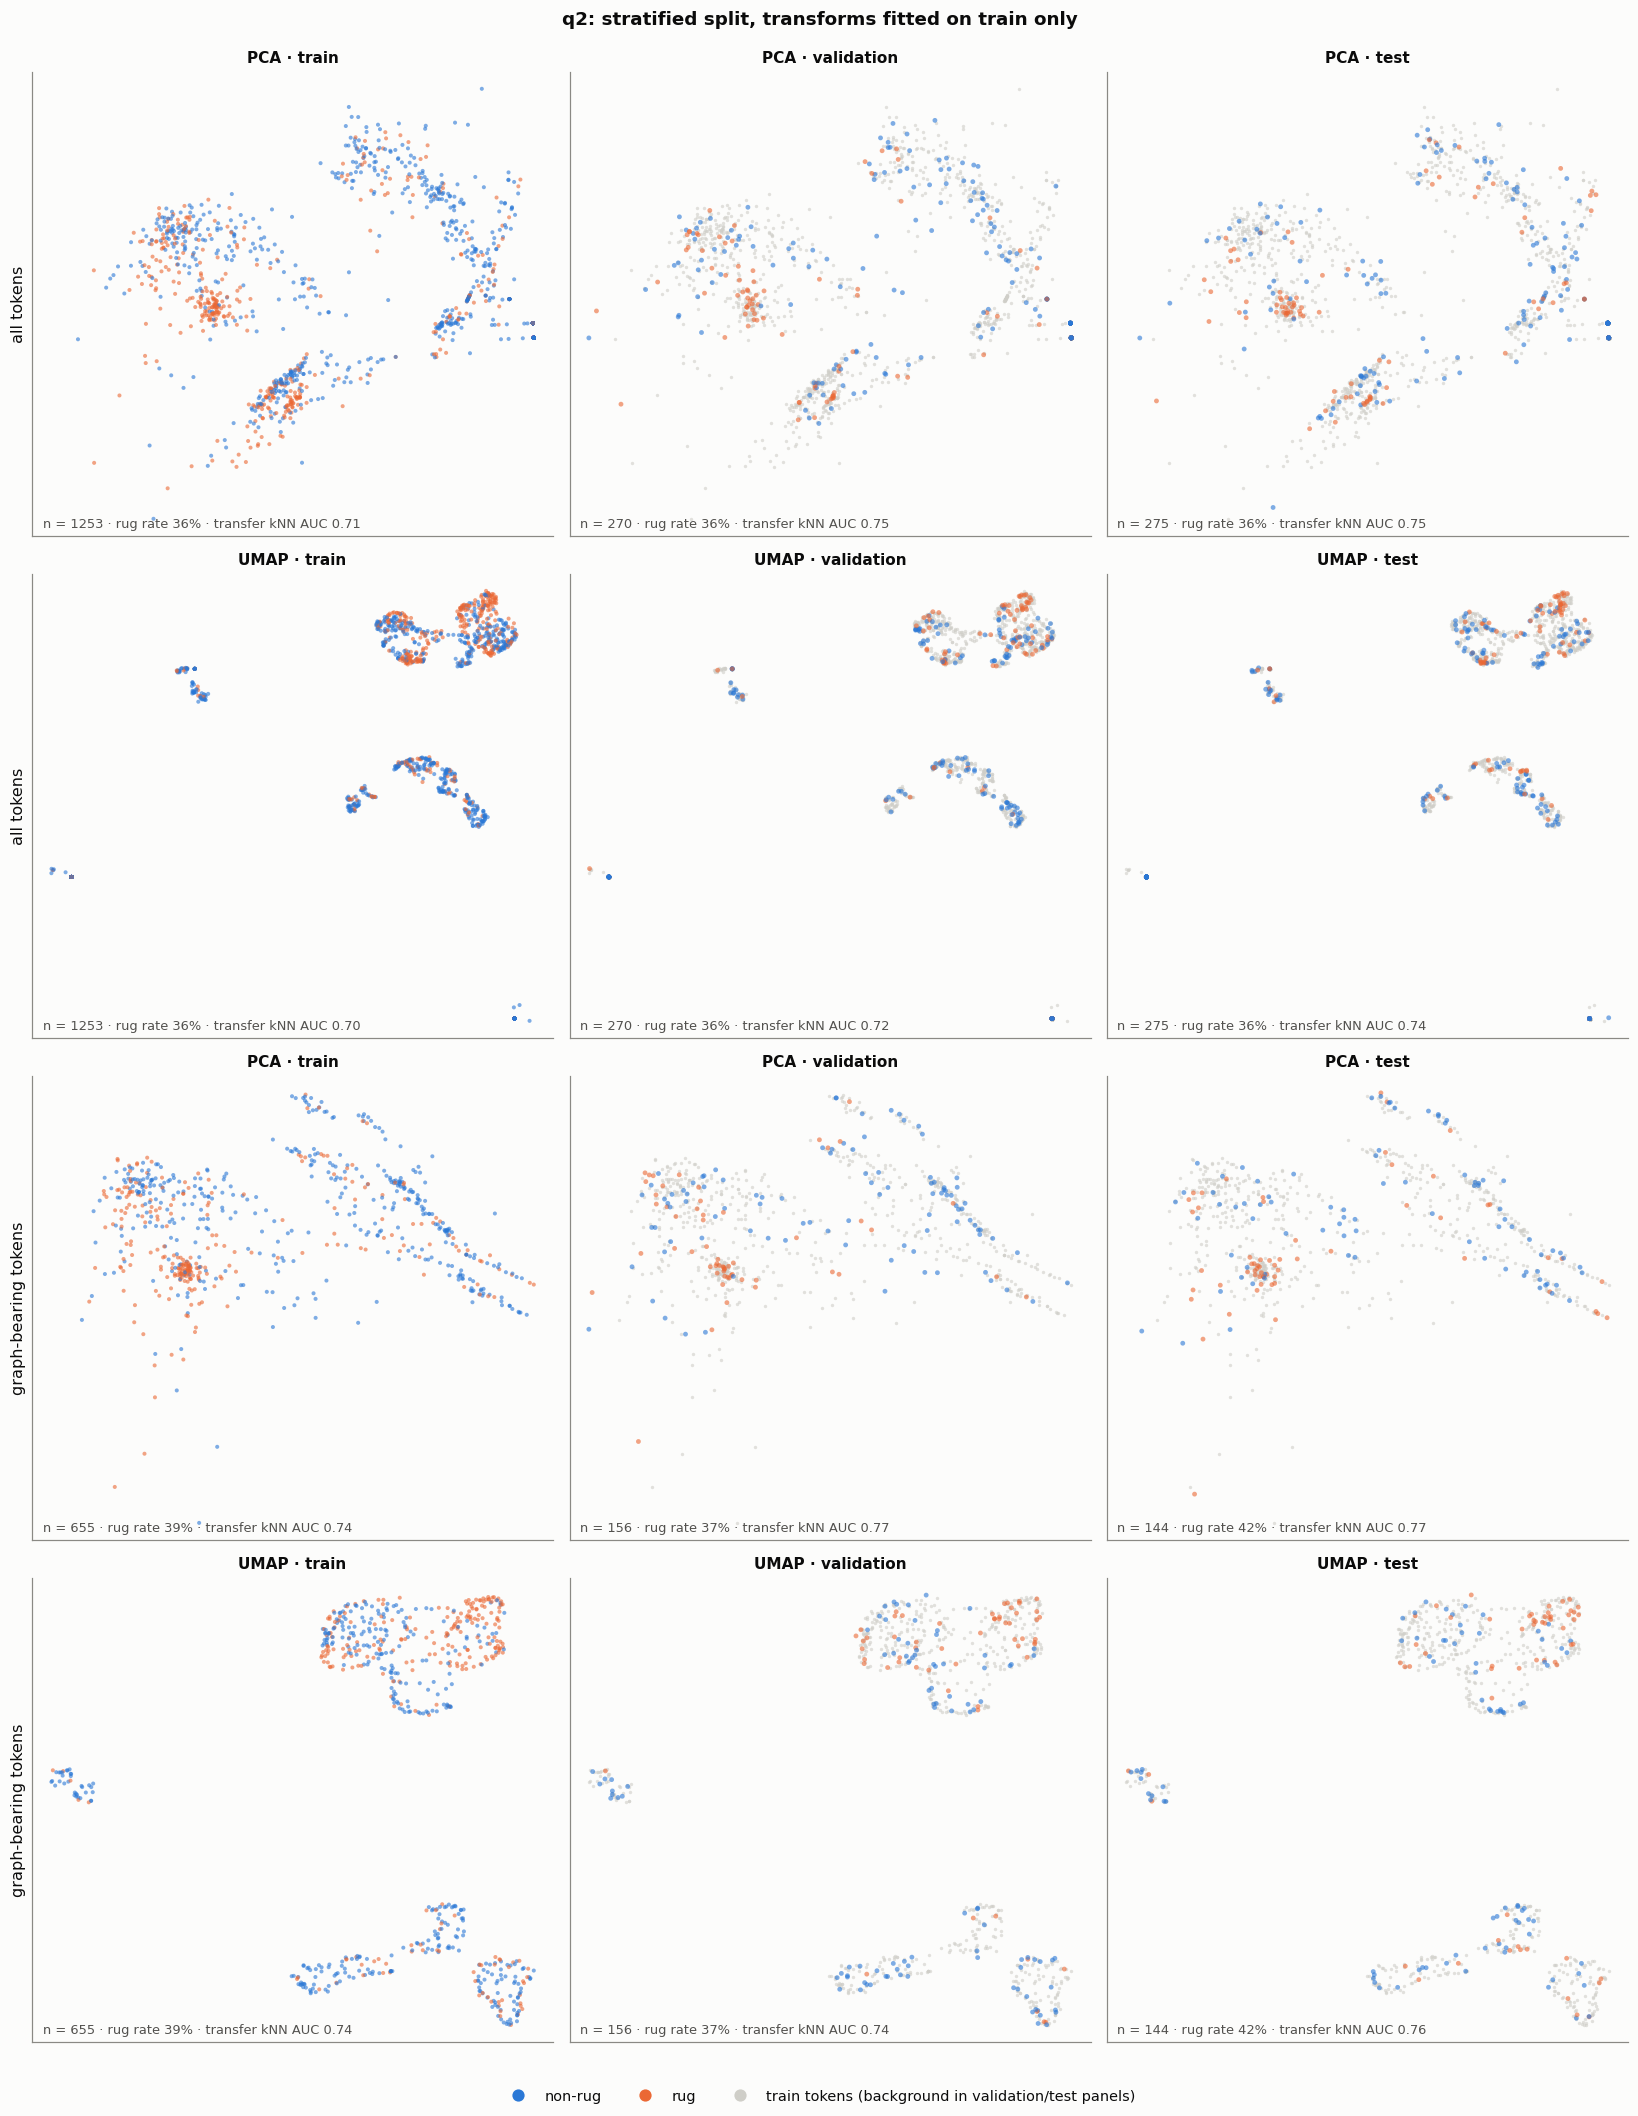

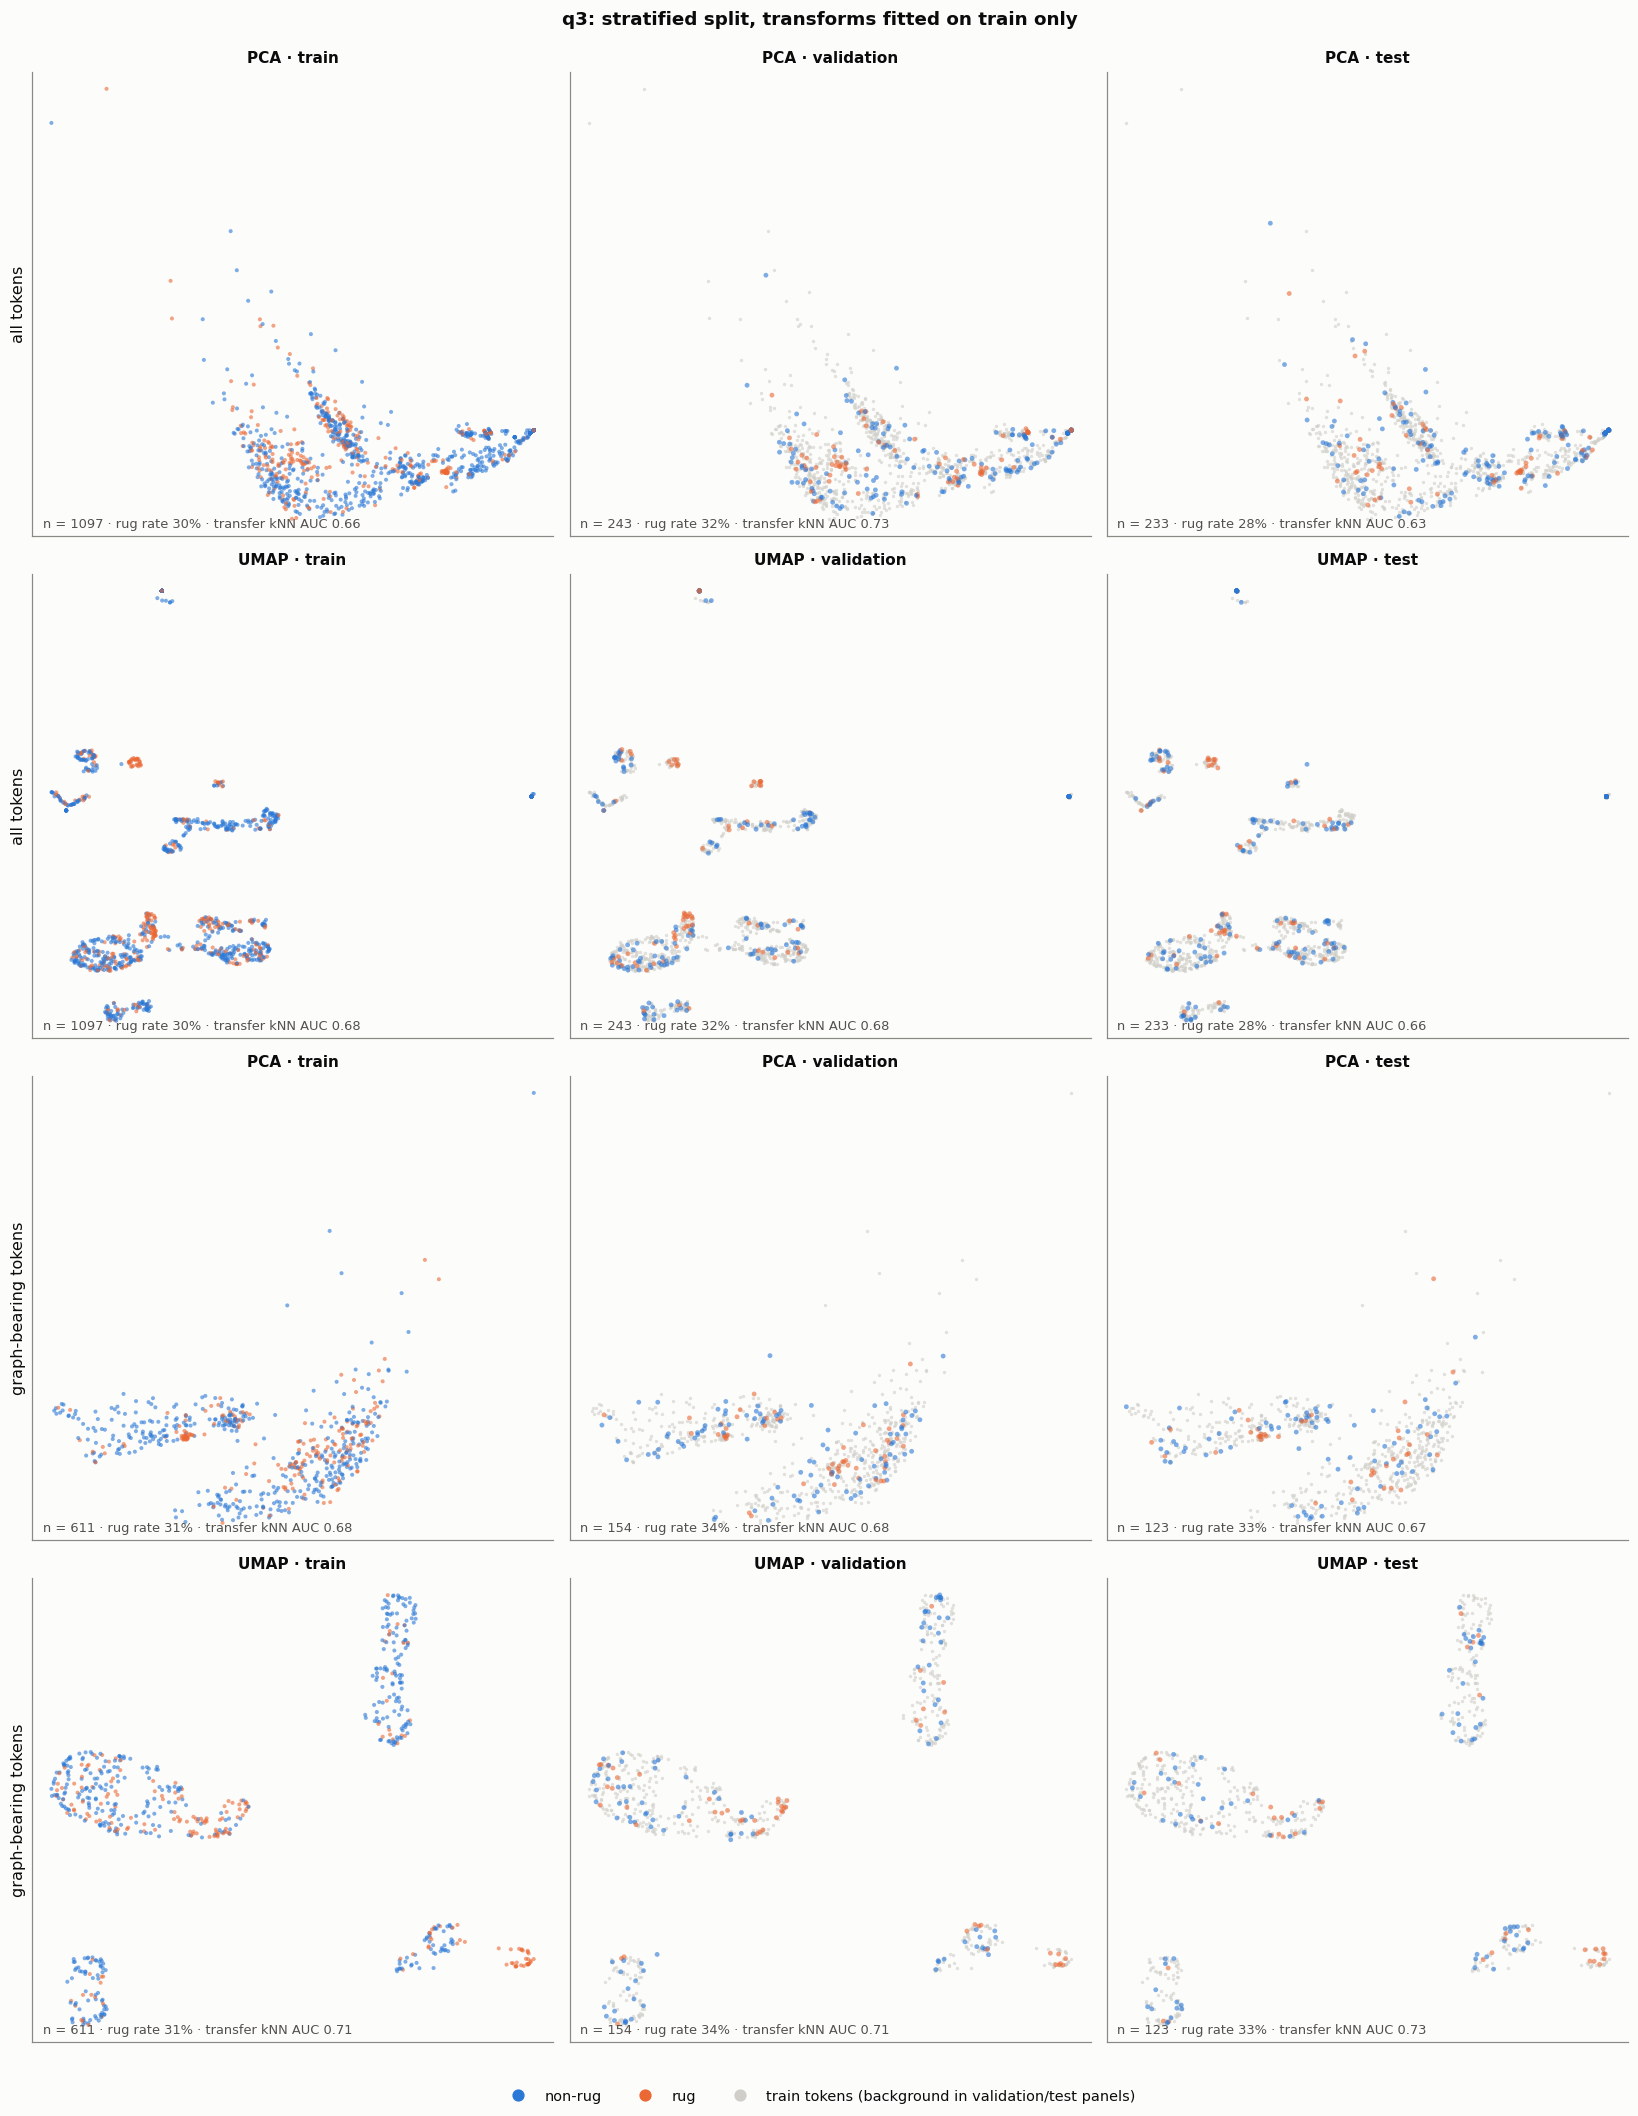

In [ ]:
def plot_strat(q):
    fig, axes = plt.subplots(4, 3, figsize=(15, 19.5))
    row = 0
    for pop in STRAT_POPULATIONS:
        d, spaces = strat_emb[(q, pop)]
        y = d['rug_pull_label'].to_numpy()
        split = d['split'].to_numpy()
        tr = split == 'train'
        for space in ['PCA', 'UMAP']:
            E = spaces[space]
            pad = 0.04 * (E.max(axis=0) - E.min(axis=0))
            lo, hi = E.min(axis=0) - pad, E.max(axis=0) + pad
            for j, sp in enumerate(SPLITS):
                ax = axes[row, j]
                m = split == sp
                if sp != 'train':
                    ax.scatter(E[tr, 0], E[tr, 1], s=5, color=SPLIT_GRAY, alpha=0.6, linewidths=0,
                               rasterized=True)
                scatter_classes(ax, E[m], y[m], s=10 if sp != 'train' else 7)
                ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1])
                r = strat_sep.query('window == @q and population == @pop and space == @space '
                                    'and split == @sp').iloc[0]
                ax.set_title(f'{space} · {sp}', fontsize=10)
                ax.text(0.02, 0.02, f'n = {m.sum()} · rug rate {y[m].mean():.0%} · '
                                    f'transfer kNN AUC {r["transfer kNN AUC"]:.2f}',
                        transform=ax.transAxes, fontsize=8.5, color='#52514e')
                if j == 0:
                    ax.set_ylabel(pop, fontsize=10.5)
            row += 1
    handles = class_handles() + [Line2D([], [], marker='o', ls='', color=SPLIT_GRAY, markersize=7,
                                        label='train tokens (background in validation/test panels)')]
    fig.suptitle(f'{q}: stratified split, transforms fitted on train only',
                 fontsize=12, fontweight='semibold')
    fig.tight_layout(rect=(0, 0.025, 1, 0.985))
    fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=9.5)
    savefig(fig, f'07_stratified_split_{q}')
    plt.show()

for q in EXPERIMENTS:
    plot_strat(q)

In [ ]:
# Stratified vs chronological: does a held-out partition still transfer from train?
cmp = pd.concat([
    strat_sep.query('population == "all tokens"').assign(scheme='stratified'),
    chrono_sep.assign(scheme='chronological'),
]).query('space == "full"')
cmp.pivot_table(index=['scheme', 'split'], columns='window', values=['rug rate', 'transfer kNN AUC'],
                sort=False).round(3)

NameError: name 'pd' is not defined

**<span style="color:red">Observation:</span>** **The stratified split behaves as intended.** All three partitions have the same rug rate (q1: 39 / 39 / 39 %; q3: 30 / 32 / 28 %). Validation and test tokens fall inside the training cloud in every PCA and UMAP panel, with no regions empty in train and none new in test. Rug-rich and non-rug regions sit in the same places across partitions.<br><br>**Train-fitted structure transfers to held-out tokens.**<br>* **All tokens:** transfer kNN AUC in the full space is 0.69–0.74 for validation and test, the same as within train (0.69–0.71). One exception is the q3 test split (0.64), which also has the lowest rug rate (28 %). With about 230 tokens and 66 rugs, that is within sampling noise but worth remembering when reading q3 test results.<br>* **Graph-bearing tokens** separate better than all tokens: 0.73–0.81 in the full space, and UMAP test 0.73–0.77. This matches Section 7: once a transfer graph exists, sender concentration and graph size add signal beyond the activity/missingness split.<br><br>**Stratified vs chronological** (last table, full space, all tokens):<br>* Under the stratified split, held-out transfer scores (0.64–0.74) are about the same as within train, and rug rates match.<br>* Under the chronological split, validation is inflated (0.77–0.81 at a 45–56 % rug rate) and test is deflated (0.59–0.67 at 23–29 %).<br><br>The gap between the two schemes is the cost of time drift. Stratified test scores estimate in-distribution performance; chronological test scores estimate performance on genuinely later tokens, and are lower.

# 8. Multivariate Separability Reference (Cross-Validated)

The projections are visual. This section asks the same question with simple classifiers, as a
reference point for the trained models rather than as a model result. Each score is the mean ± SD
ROC-AUC over 3 × 5-fold stratified CV on train + validation. Imputation and scaling are fitted
inside each fold.

* **flags only**: the six missing/observed indicators alone, via logistic regression;
* **values only**: transformed values, median-imputed without indicators, via logistic regression;
* **values + flags**: both, via logistic regression;
* **gradient boosting**: all registry features with native NaN handling, plus the variant with the
  `pump` mint suffix added (see Section 10).

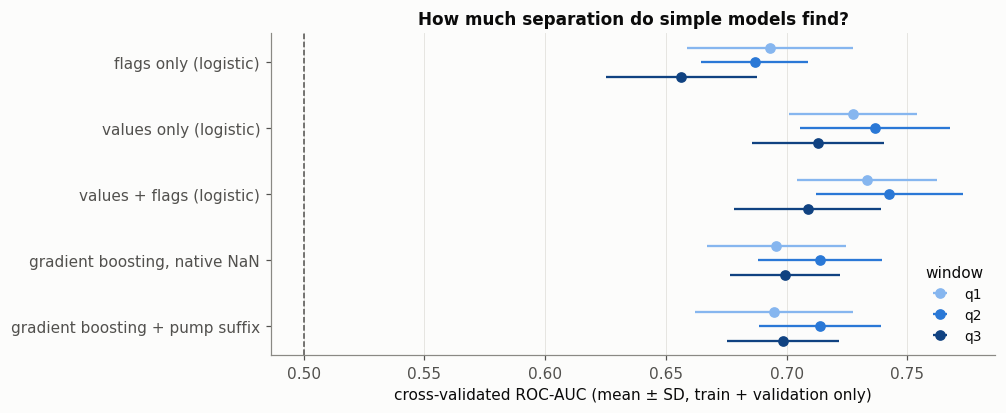

window,q1,q2,q3
setup,,,
flags only (logistic),0.6932,0.6868,0.6564
values only (logistic),0.7277,0.7366,0.7129
values + flags (logistic),0.7333,0.7426,0.7087
"gradient boosting, native NaN",0.6958,0.7138,0.6993
gradient boosting + pump suffix,0.6948,0.7138,0.6986


In [ ]:
def cv_auc(estimator, X, y, repeats=3):
    scores = [s for r in range(repeats)
              for s in cross_val_score(estimator, X, y, scoring='roc_auc',
                                       cv=StratifiedKFold(5, shuffle=True, random_state=SEED + r))]
    return np.mean(scores), np.std(scores)

logit = lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                              LogisticRegression(max_iter=5000, class_weight='balanced'))
hgb = lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                             min_samples_leaf=20, class_weight='balanced',
                                             random_state=SEED)
cv_rows = []
for q in EXPERIMENTS:
    d = dev[q]
    y = d['rug_pull_label'].to_numpy()
    flags = (~presence_flags(d)).astype(float).add_prefix('missing: ')
    values = pd.DataFrame({c: tf(d, c) for c in DR_NODE + DR_GRAPH}).assign(
        has_initial_freeze_authority=d['has_initial_freeze_authority'].astype(float))
    full_values = pd.DataFrame({c: tf(d, c) for c in FEATS_ALL}).assign(
        has_initial_freeze_authority=d['has_initial_freeze_authority'].astype(float))
    setups = {
        'flags only (logistic)': (logit(), flags),
        'values only (logistic)': (logit(), values),
        'values + flags (logistic)': (logit(), pd.concat([values, flags], axis=1)),
        'gradient boosting, native NaN': (hgb(), full_values),
        'gradient boosting + pump suffix': (hgb(), full_values.assign(is_pump_mint=d['is_pump_mint'].astype(float))),
    }
    for name, (est, X) in setups.items():
        m, s = cv_auc(est, X, y)
        cv_rows.append({'window': q, 'setup': name, 'AUC mean': m, 'AUC sd': s})
cv_table = pd.DataFrame(cv_rows)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
setups_order = list(dict.fromkeys(cv_table['setup']))
for j, q in enumerate(EXPERIMENTS):
    t = cv_table[cv_table.window == q].set_index('setup').reindex(setups_order)
    yy = np.arange(len(t)) + (j - 1) * 0.22
    ax.errorbar(t['AUC mean'], yy, xerr=t['AUC sd'], fmt='o', color=WINDOW_COLORS[q], ms=6, lw=1.5,
                capsize=0, label=q)
ax.axvline(0.5, color='#52514e', lw=1, ls='--')
ax.set_yticks(range(len(setups_order)), setups_order)
ax.invert_yaxis()
ax.set_xlabel('cross-validated ROC-AUC (mean ± SD, train + validation only)')
ax.set_title('How much separation do simple models find?')
ax.legend(title='window', loc='lower right')
ax.grid(axis='y', visible=False)
savefig(fig, '08_cv_reference')
plt.show()
cv_table.pivot(index='setup', columns='window', values='AUC mean').reindex(setups_order)

**<span style="color:red">Observation:</span>** With simple models and cross-validation (train + validation only):<br>* **Missingness flags alone:** AUC 0.66–0.69.<br>* **Values (median-imputed):** 0.71–0.74.<br>* **Values + flags:** 0.71–0.74. This adds about 0.005 in q1/q2 and nothing in q3, partly because the median-imputed values already reveal which entries were missing.<br>* **Gradient boosting with native NaN on all registry features:** 0.70–0.71. It is *not* better than regularised logistic regression, a sign of the small sample (~1.3k–1.7k tokens), noisy heavy-tailed features and weak individual effects.<br>* **Adding the `pump` suffix:** changes nothing (Δ ≤ 0.001).<br><br>These figures roughly bound what the token + graph-summary features support (about 0.70–0.75 ROC-AUC). The GNN has to gain over this level by using structure beyond these summary statistics.

# 9. Unsupervised Baselines: Two-Class Anomaly Detection and Two-Cluster Clustering

Can the label be recovered **without using it**? Two families of unsupervised models each split the
tokens into two groups, and the groups are then compared with `rug_pull_label`. Labels are used
only for this evaluation, never for fitting. Inputs are the same standardised matrices as Section 7
(views A, B and C, train + validation rows).

**Anomaly detection (normal vs anomalous).** If rugs were "unusual" tokens, anomaly scores would rank
them high.
* **Isolation Forest**: how easily random splits isolate a point;
* **Local Outlier Factor** (k = 30): local density relative to neighbours;
* **One-Class SVM** (RBF): distance outside a learned support region.

Each method gives a continuous score and a binary flag. Two flagging rates are shown:
**5 %**, a conventional anomaly budget, and **= rug prevalence**, a deliberately label-informed best
case that gives the detector exactly as many flags as there are rugs. The threshold-free comparison is
the **AUC of the anomaly score**: above 0.5 means anomalous ≈ rug, below 0.5 means anomalous ≈ non-rug.

**Clustering (k = 2).**
* **k-means**: spherical clusters, Euclidean;
* **Gaussian mixture** (full covariance): elliptical clusters, soft assignment;
* **Agglomerative (Ward)**: hierarchical merge of variance-minimising groups.

Cluster ids are arbitrary, so agreement is measured with label-permutation-invariant scores:
**ARI** (adjusted Rand index; 0 = chance, 1 = identical partition), **NMI** (normalised mutual
information), and **balanced accuracy / rug F1 under the better of the two cluster→label mappings**.

In [ ]:
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, balanced_accuracy_score, f1_score,
                             normalized_mutual_info_score, precision_score, recall_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

# Hundreds of inactive tokens share an identical feature vector; LOF warns about these real duplicates.
warnings.filterwarnings('ignore', message='Duplicate values are leading to incorrect results')

def anomaly_scores(Z):
    """Higher = more anomalous, for each detector."""
    iso = IsolationForest(n_estimators=500, random_state=SEED).fit(Z)
    lof = LocalOutlierFactor(n_neighbors=30).fit(Z)
    ocs = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05).fit(Z)
    return {
        'Isolation Forest': -iso.score_samples(Z),
        'Local Outlier Factor': -lof.negative_outlier_factor_,
        'One-Class SVM': -ocs.decision_function(Z),
    }

def flag_top(score, rate):
    return (score >= np.quantile(score, 1 - rate)).astype(int)

def cluster_two(Z):
    return {
        'k-means': KMeans(2, n_init=20, random_state=SEED).fit_predict(Z),
        'Gaussian mixture': GaussianMixture(2, covariance_type='full', n_init=5,
                                            random_state=SEED).fit_predict(Z),
        'Agglomerative (Ward)': AgglomerativeClustering(2, linkage='ward').fit_predict(Z),
    }

def binary_agreement(y, groups):
    """Agreement of a 2-group partition with y; group->label mapping chosen to favour rug detection."""
    ari = adjusted_rand_score(y, groups)
    nmi = normalized_mutual_info_score(y, groups)
    best = max(((groups == g).astype(int) for g in np.unique(groups)),
               key=lambda pred: balanced_accuracy_score(y, pred))
    rug_group_rate = y[best == 1].mean()
    return {
        'ARI': ari, 'NMI': nmi,
        'balanced acc.': balanced_accuracy_score(y, best),
        'rug precision': precision_score(y, best, zero_division=0),
        'rug recall': recall_score(y, best),
        'rug F1': f1_score(y, best),
        'size of "rug" group': best.mean(),
        'rug rate in "rug" group': rug_group_rate,
        'rug rate in other group': y[best == 0].mean(),
    }, best

unsup_rows, unsup_assign = [], {}
for q in EXPERIMENTS:
    for v in VIEWS:
        Z, _, d = mats[(q, v)]
        y = d['rug_pull_label'].to_numpy()
        for name, s in anomaly_scores(Z).items():
            for rate_name, rate in [('5 %', 0.05), ('= prevalence', y.mean())]:
                flags = flag_top(s, rate)
                stats_, _ = binary_agreement(y, flags)
                # for anomalies the mapping is fixed (anomaly = rug); report it as such
                stats_.update({
                    'balanced acc.': balanced_accuracy_score(y, flags),
                    'rug precision': precision_score(y, flags, zero_division=0),
                    'rug recall': recall_score(y, flags), 'rug F1': f1_score(y, flags),
                    'size of "rug" group': flags.mean(),
                    'rug rate in "rug" group': y[flags == 1].mean(),
                    'rug rate in other group': y[flags == 0].mean(),
                })
                unsup_rows.append({'window': q, 'view': v, 'family': 'anomaly detection',
                                   'method': name, 'setting': f'flag rate {rate_name}',
                                   'score AUC': roc_auc_score(y, s), **stats_})
                unsup_assign[(q, v, name, rate_name)] = flags
        for name, groups in cluster_two(Z).items():
            stats_, best = binary_agreement(y, groups)
            unsup_rows.append({'window': q, 'view': v, 'family': 'clustering', 'method': name,
                               'setting': 'k = 2', 'score AUC': np.nan, **stats_})
            unsup_assign[(q, v, name, 'k=2')] = best
unsup = pd.DataFrame(unsup_rows)
show_cols = ['family', 'method', 'setting', 'score AUC', 'ARI', 'NMI', 'balanced acc.', 'rug precision',
             'rug recall', 'rug F1', 'size of "rug" group', 'rug rate in "rug" group', 'rug rate in other group']
print('q1 · view A (all tokens), rug prevalence', f"{dev['q1'].rug_pull_label.mean():.1%}")
unsup.query('window == "q1" and view == "A: all tokens"')[show_cols].set_index(['family', 'method', 'setting'])

q1 · view A (all tokens), rug prevalence 39.0%


score AUC       ARI       NMI  balanced acc.  rug precision  rug recall  rug F1  size of "rug" group  rug rate in "rug" group  \
family            method               setting                                                                                                                                                 
anomaly detection Isolation Forest     flag rate 5 %              0.5988   0.01173   0.00447         0.5142         0.5238     0.06769  0.1199              0.05042                   0.5238   
                                       flag rate = prevalence     0.5988   0.01429  0.005606         0.5434         0.4431      0.4431  0.4431               0.3902                   0.4431   
                  Local Outlier Factor flag rate 5 %              0.6078   0.01061  0.003714         0.5129         0.5119     0.06615  0.1172              0.05042                   0.5119   
                                       flag rate = prevalence     0.6078   0.05095   0.02764         0.5964         0.5077      0.5077  0.5077               0.3902                   0.5077   
                  One-Class SVM        flag rate 5 %               0.439  0.002427 0.0001948         0.5033         0.4151     0.06769  0.1164              0.06363                   0.4151   
                                       flag rate = prevalence      0.439 -0.002765  0.001162         0.4803         0.3662      0.3662  0.3662               0.3902                   0.3662   
clustering        k-means              k = 2                         NaN    0.1129   0.06686         0.6458         0.5867      0.5308  0.5574               0.3529                   0.5867   
                  Gaussian mixture     k = 2                         NaN    0.1129   0.06686         0.6458         0.5867      0.5308  0.5574               0.3529                   0.5867   
                  Agglomerative (Ward) k = 2                         NaN    0.1129   0.06686         0.6458         0.5867      0.5308  0.5574               0.3529                   0.5867   

                                                               rug rate in other group  
family            method               setting                                          
anomaly detection Isolation Forest     flag rate 5 %                            0.3831  
                                       flag rate = prevalence                   0.3563  
                  Local Outlier Factor flag rate 5 %                            0.3837  
                                       flag rate = prevalence                    0.315  
                  One-Class SVM        flag rate 5 %                            0.3885  
                                       flag rate = prevalence                   0.4055  
clustering        k-means              k = 2                                    0.2829  
                  Gaussian mixture     k = 2                                    0.2829  
                  Agglomerative (Ward) k = 2                                    0.2829

In [ ]:
# All windows and views: headline numbers only.
headline = unsup.assign(key=unsup['method'] + ' · ' + unsup['setting'])
(headline.pivot_table(index=['view', 'family', 'key'], columns='window',
                      values=['score AUC', 'ARI', 'balanced acc.'], sort=False)
 .round(3))

score AUC                ARI               balanced acc.            
window                                                                                                q1    q2    q3     q1     q2     q3            q1    q2    q3
view                           family            key                                                                                                               
A: all tokens                  anomaly detection Isolation Forest · flag rate 5 %                  0.599 0.485 0.506  0.012 -0.011 -0.015         0.514 0.489 0.489
                                                 Isolation Forest · flag rate = prevalence         0.599 0.485 0.506  0.014 -0.007  0.003         0.543 0.465 0.507
                                                 Local Outlier Factor · flag rate 5 %              0.608 0.569 0.488  0.011  0.008 -0.015         0.513 0.508 0.489
                                                 Local Outlier Factor · flag rate = prevalence     0.608 0.569 0.488  0.051  0.026 -0.008         0.596 0.555 0.484
                                                 One-Class SVM · flag rate 5 %                     0.439 0.379 0.488  0.002 -0.008 -0.008         0.503 0.492 0.494
                                                 One-Class SVM · flag rate = prevalence            0.439 0.379 0.488 -0.003 -0.003  0.005          0.48 0.422  0.51
                               clustering        k-means · k = 2                                     NaN   NaN   NaN  0.113  0.086 -0.002         0.646 0.658 0.541
                                                 Gaussian mixture · k = 2                            NaN   NaN   NaN  0.113  0.084 -0.002         0.646 0.657 0.541
                                                 Agglomerative (Ward) · k = 2                        NaN   NaN   NaN  0.113  0.084 -0.002         0.646 0.657 0.541
B: graph recovered             anomaly detection Isolation Forest · flag rate 5 %                  0.527 0.362 0.445  0.001 -0.015 -0.027         0.502  0.48 0.478
                                                 Isolation Forest · flag rate = prevalence         0.527 0.362 0.445  0.005  0.013 -0.014         0.531 0.404 0.463
                                                 Local Outlier Factor · flag rate 5 %              0.613 0.575 0.461  0.011  0.011 -0.006          0.52 0.513 0.496
                                                 Local Outlier Factor · flag rate = prevalence     0.613 0.575 0.461  0.026  0.018 -0.014         0.575  0.55 0.463
                                                 One-Class SVM · flag rate 5 %                     0.454 0.404 0.487  0.008 -0.008 -0.009         0.515  0.49 0.493
                                                 One-Class SVM · flag rate = prevalence            0.454 0.404 0.487 -0.002 -0.001   0.01         0.491 0.443 0.521
                               clustering        k-means · k = 2                                     NaN   NaN   NaN    0.1  0.072 -0.007         0.658 0.662 0.532
                                                 Gaussian mixture · k = 2                            NaN   NaN   NaN    0.1  0.071 -0.007         0.658 0.661 0.533
                                                 Agglomerative (Ward) · k = 2                        NaN   NaN   NaN    0.1  0.065 -0.007         0.658 0.657 0.532
C: complete cases, values only anomaly detection Isolation Forest · flag rate 5 %                  0.515 0.461 0.535 -0.024  0.011 -0.002         0.521  0.48 0.498
                                                 Isolation Forest · flag rate = prevalence         0.515 0.461 0.535  0.012 -0.001 -0.004          0.53  0.47 0.494
                                                 Local Outlier Factor · flag rate 5 %              0.548 0.499 0.435 -0.016  0.005 -0.002         0.513  0.49 0.498
                                                 Local Outlier Factor · flag rate = prevalence     0.548 0.499 0.435  0.029 -0.003 -0.002         0.554 0.495 0

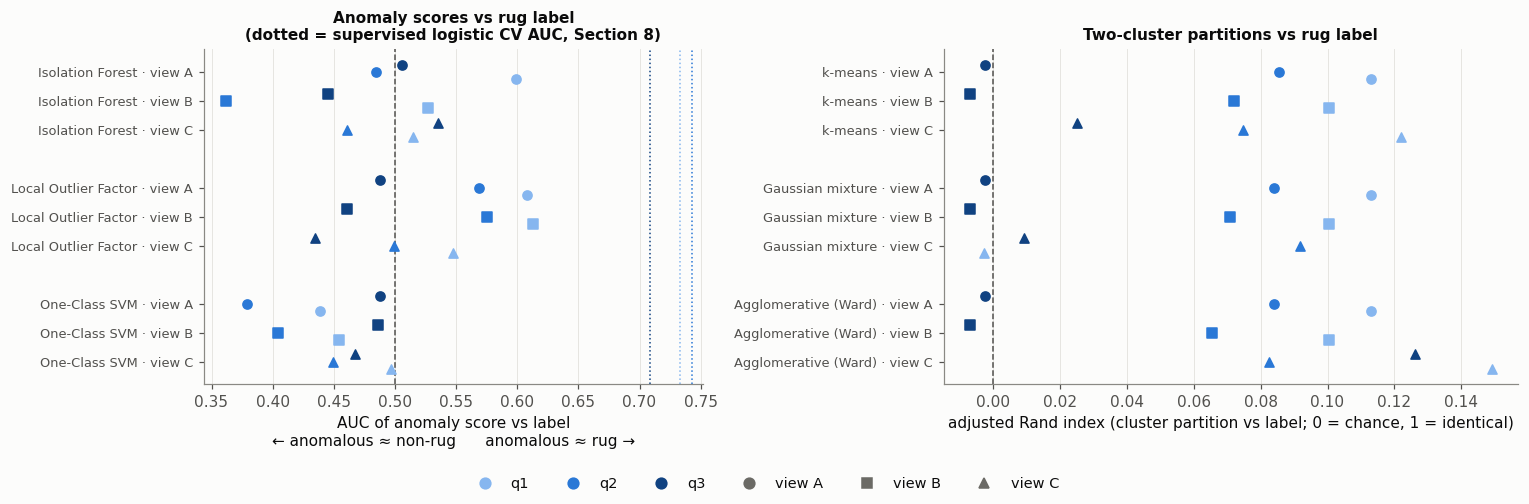

In [ ]:
# Reference line: the supervised logistic model from Section 8 on the same rows (view A ≈ all tokens).
sup_ref = cv_table.query('setup == "values + flags (logistic)"').set_index('window')['AUC mean']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1, 1.15]})
ax = axes[0]
an = unsup.query('family == "anomaly detection" and setting == "flag rate 5 %"')
methods_a = list(dict.fromkeys(an['method']))
for j, q in enumerate(EXPERIMENTS):
    for i, v in enumerate(VIEWS):
        t = an.query('window == @q and view == @v').set_index('method').reindex(methods_a)
        yy = np.arange(len(methods_a)) * 4 + i + (1 - j) * 0.25
        ax.scatter(t['score AUC'], yy, color=WINDOW_COLORS[q], s=36, marker='os^'[i], zorder=3,
                   label=f'{q}' if i == 0 else None)
ax.axvline(0.5, color='#52514e', lw=1, ls='--')
for q in EXPERIMENTS:
    ax.axvline(sup_ref[q], color=WINDOW_COLORS[q], lw=1, ls=':')
ax.set_yticks([k * 4 + i for k in range(len(methods_a)) for i in range(3)],
              [f'{m} · view {v[0]}' for m in methods_a for v in VIEWS], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('AUC of anomaly score vs label\n← anomalous ≈ non-rug      anomalous ≈ rug →')
ax.set_title('Anomaly scores vs rug label\n(dotted = supervised logistic CV AUC, Section 8)', fontsize=10)
ax.grid(axis='y', visible=False)

ax = axes[1]
cl = unsup.query('family == "clustering"')
methods_c = list(dict.fromkeys(cl['method']))
for j, q in enumerate(EXPERIMENTS):
    for i, v in enumerate(VIEWS):
        t = cl.query('window == @q and view == @v').set_index('method').reindex(methods_c)
        yy = np.arange(len(methods_c)) * 4 + i + (1 - j) * 0.25
        ax.scatter(t['ARI'], yy, color=WINDOW_COLORS[q], s=36, marker='os^'[i], zorder=3,
                   label=f'{q}' if i == 0 else None)
ax.axvline(0, color='#52514e', lw=1, ls='--')
ax.set_yticks([k * 4 + i for k in range(len(methods_c)) for i in range(3)],
              [f'{m} · view {v[0]}' for m in methods_c for v in VIEWS], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel('adjusted Rand index (cluster partition vs label; 0 = chance, 1 = identical)')
ax.set_title('Two-cluster partitions vs rug label', fontsize=10)
ax.grid(axis='y', visible=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=WINDOW_COLORS[q], markersize=7, label=q)
                    for q in EXPERIMENTS]
                   + [Line2D([], [], marker=mk, ls='', color=NEUTRAL, markersize=7, label=f'view {v[0]}')
                      for mk, v in zip('os^', VIEWS)],
           loc='lower center', ncol=6, fontsize=9.5)
savefig(fig, '09_unsupervised_vs_labels')
plt.show()

In [ ]:
# Contingency tables, q1 view A: who ends up in which group?
def contingency(q, v, name, setting, group_names):
    _, _, d = mats[(q, v)]
    g = unsup_assign[(q, v, name, setting)]
    group = pd.Series(np.where(g == 1, group_names[1], group_names[0]), index=d.index, name='group')
    t = pd.crosstab(group, d['rug_pull_label'].map(CLASS_NAMES).rename('label'))
    t['rug rate'] = t['rug'] / t[['non-rug', 'rug']].sum(axis=1)
    t['mean observed blocks'] = d.groupby(group)['n_observed'].mean()
    t['share with graph'] = d.groupby(group)['has_graph'].mean()
    return t.reindex(list(group_names))

for name, setting, names in [
    ('Isolation Forest', '= prevalence', ('normal', 'anomalous')),
    ('One-Class SVM', '= prevalence', ('normal', 'anomalous')),
    ('k-means', 'k=2', ('cluster → non-rug', 'cluster → rug')),
    ('Gaussian mixture', 'k=2', ('cluster → non-rug', 'cluster → rug')),
    ('Agglomerative (Ward)', 'k=2', ('cluster → non-rug', 'cluster → rug')),
]:
    print(f'\nq1 · view A · {name} ({setting})')
    display(contingency('q1', 'A: all tokens', name, setting, names).round(3))


q1 · view A · Isolation Forest (= prevalence)


label,non-rug,rug,rug rate,mean observed blocks,share with graph
group,,,,,
normal,654,362,0.356,2.326,0.34
anomalous,362,288,0.443,3.771,0.671



q1 · view A · One-Class SVM (= prevalence)


label,non-rug,rug,rug rate,mean observed blocks,share with graph
group,,,,,
normal,604,412,0.406,3.237,0.54
anomalous,412,238,0.366,2.346,0.357



q1 · view A · k-means (k=2)


label,non-rug,rug,rug rate,mean observed blocks,share with graph
group,,,,,
cluster → non-rug,773,305,0.283,1.525,0.387
cluster → rug,243,345,0.587,5.391,0.619



q1 · view A · Gaussian mixture (k=2)


label,non-rug,rug,rug rate,mean observed blocks,share with graph
group,,,,,
cluster → non-rug,773,305,0.283,1.525,0.387
cluster → rug,243,345,0.587,5.391,0.619



q1 · view A · Agglomerative (Ward) (k=2)


label,non-rug,rug,rug rate,mean observed blocks,share with graph
group,,,,,
cluster → non-rug,773,305,0.283,1.525,0.387
cluster → rug,243,345,0.587,5.391,0.619


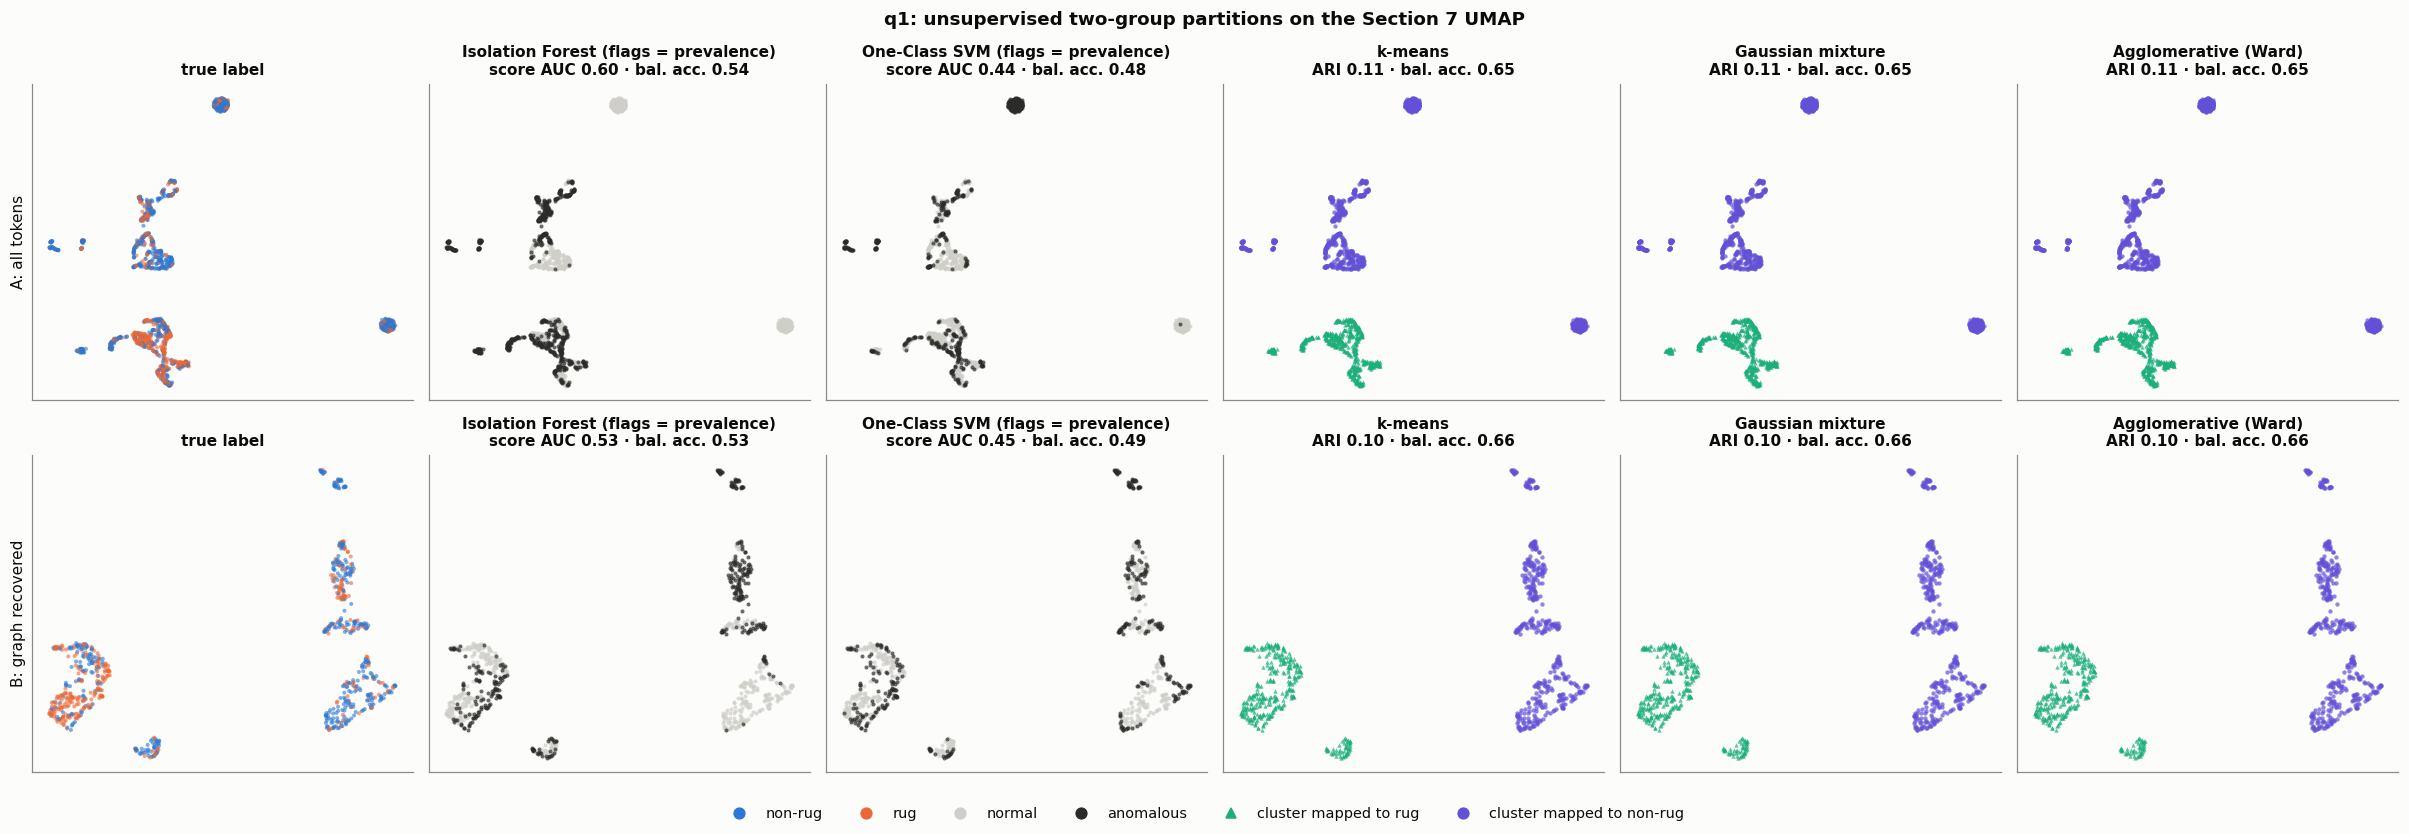

In [ ]:
# Where the unsupervised groups sit in the UMAP of Section 7 (q1, views A and B).
CLUSTER_COLORS = ('#6250d6', '#1baf7a')   # violet / aqua: distinct from the class blue/orange
ANOMALY_COLOR, NORMAL_COLOR = '#2b2b29', '#cfcec8'

def scatter_groups(ax, E, g, colors, markers=('o', '^'), s=8):
    order = np.random.default_rng(SEED).permutation(len(g))
    for k in (0, 1):
        m = g[order] == k
        ax.scatter(E[order][m, 0], E[order][m, 1], s=s, color=colors[k], marker=markers[k], alpha=0.7,
                   linewidths=0, rasterized=True)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

panels = [('label', None), ('Isolation Forest', '= prevalence'), ('One-Class SVM', '= prevalence'),
          ('k-means', 'k=2'), ('Gaussian mixture', 'k=2'), ('Agglomerative (Ward)', 'k=2')]
fig, axes = plt.subplots(2, len(panels), figsize=(22, 7.6))
for i, v in enumerate(['A: all tokens', 'B: graph recovered']):
    _, _, d = mats[('q1', v)]
    y = d['rug_pull_label'].to_numpy()
    E = emb[('q1', v, 'UMAP')]
    for j, (name, setting) in enumerate(panels):
        ax = axes[i, j]
        if name == 'label':
            scatter_classes(ax, E, y)
            ax.set_title('true label', fontsize=10)
        else:
            g = unsup_assign[('q1', v, name, setting)]
            r = unsup.query('window == "q1" and view == @v and method == @name and '
                            '(setting == "k = 2" or setting == "flag rate = prevalence")').iloc[0]
            if setting == 'k=2':
                scatter_groups(ax, E, g, CLUSTER_COLORS)
                ax.set_title(f'{name}\nARI {r["ARI"]:.2f} · bal. acc. {r["balanced acc."]:.2f}', fontsize=10)
            else:
                scatter_groups(ax, E, g, (NORMAL_COLOR, ANOMALY_COLOR), markers=('o', 'o'), s=7)
                ax.set_title(f'{name} (flags = prevalence)\nscore AUC {r["score AUC"]:.2f} · '
                             f'bal. acc. {r["balanced acc."]:.2f}', fontsize=10)
        if j == 0:
            ax.set_ylabel(v, fontsize=10)
legend_handles = class_handles() + [
    Line2D([], [], marker='o', ls='', color=NORMAL_COLOR, markersize=7, label='normal'),
    Line2D([], [], marker='o', ls='', color=ANOMALY_COLOR, markersize=7, label='anomalous'),
    Line2D([], [], marker='^', ls='', color=CLUSTER_COLORS[1], markersize=7,
           label='cluster mapped to rug'),
    Line2D([], [], marker='o', ls='', color=CLUSTER_COLORS[0], markersize=7,
           label='cluster mapped to non-rug'),
]
fig.suptitle('q1: unsupervised two-group partitions on the Section 7 UMAP', fontsize=12,
             fontweight='semibold')
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.legend(handles=legend_handles, loc='lower center', ncol=6, fontsize=9.5)
savefig(fig, '09_unsupervised_on_umap_q1')
plt.show()

**<span style="color:red">Observation:</span>** **Anomaly detection does not recover the rug label.** Anomaly-score AUCs scatter around 0.5 (0.36–0.61 across detectors, views and windows), far below the supervised 0.71–0.74. Even when the detector is given the true prevalence as its flag rate, balanced accuracy stays at 0.42–0.60. Rugs are not statistical outliers: they are a *large* (30–39 %), fairly dense part of the population.<br><br>**The detectors disagree about what "unusual" means.**<br>* **Isolation Forest** flags *active* tokens (q1 view A anomalies: 3.8 observed blocks and 67 % with a graph, against 2.3 and 34 % for normal tokens). It reaches a slightly elevated 44 % rug rate.<br>* **One-Class SVM** flags the *sparse, inactive* tokens instead (2.3 blocks), which are mostly non-rug, so its AUC is below 0.5.<br>* The hundreds of identical inactive tokens always look "normal" to density-based methods because they sit in one dense pile.<br><br>**Two-cluster clustering finds a real, but different, split.** On view A, k-means, the Gaussian mixture and Ward clustering produce the *same* partition. It is the activity split: an inactive cluster (1.5 observed blocks on average, 28 % rugs, 1,078 tokens) and an active cluster (5.4 blocks, 59 % rugs, 588 tokens). Mapping the active cluster to "rug" gives balanced accuracy 0.65, rug recall 0.53 and precision 0.59, but ARI is only 0.11 (NMI 0.07). The clusters are mostly *not* the labels.<br><br>**Other views and windows.**<br>* On view B, clustering separates the trade-observed island (rug-rich lobe) from the rest, with similar quality (ARI 0.10).<br>* On complete cases (view C), Ward clustering does best (ARI 0.15, balanced accuracy 0.70 in q1). Value-only structure there aligns a little better with the label.<br>* In q3, clustering on views A and B collapses to chance (ARI ≈ 0), consistent with the fading activity signal in longer windows. Only Ward clustering on complete cases keeps some alignment (ARI 0.13).<br><br>**Conclusion.** The dominant unsupervised structure is *activity / data availability*, which correlates with rugs (Section 2) but is not the same thing. Rug detection here is not an outlier problem; anomaly detectors are poor stand-ins for the labels and should not replace supervision. The k = 2 activity cluster is still a useful one-bit summary, about as informative as the missingness flags.

# 10. Further Signals: Mint-Address Suffix and Creation Period

Mint addresses ending in `pump` are vanity addresses produced by the pump.fun launchpad. The suffix is
known at creation, so it is a legitimate pre-window attribute. It is also strongly tied to *when* a
token was created, so the two are examined together. (Temporal prevalence is analysed in more detail
in `EDA_stratified.ipynb`.)

In [ ]:
pump = pd.concat({q: dev[q].groupby('is_pump_mint')['rug_pull_label'].agg(tokens='size', rug_rate='mean')
                  for q in EXPERIMENTS}, axis=1)
display(pump)

d = dev['q1'].assign(quarter=dev['q1']['creation_utc'].dt.tz_localize(None).dt.to_period('Q').astype(str))
by_quarter = (d.groupby(['quarter', 'is_pump_mint'])['rug_pull_label'].agg(tokens='size', rug_rate='mean')
              .unstack('is_pump_mint'))
by_quarter[by_quarter[('tokens', False)].fillna(0) + by_quarter[('tokens', True)].fillna(0) >= 20]

q1              q2              q3         
             tokens rug_rate tokens rug_rate tokens rug_rate
is_pump_mint                                                
False          1280   0.4211   1151   0.3875    989   0.3266
True            386   0.2876    372   0.2715    351   0.2422

tokens       rug_rate       
is_pump_mint  False True     False  True 
quarter                                  
2023Q4           51   NaN   0.1569    NaN
2024Q1          482   NaN   0.3568    NaN
2024Q2          337    67   0.3561 0.2537
2024Q3          346   207   0.6272 0.2947
2024Q4           60   112   0.3667 0.2946

**<span style="color:red">Observation:</span>** Mint addresses ending in `pump` rug far less often: 29 % vs 42 % in q1, with the same direction in q2/q3. The effect is **not just era confounding**. Within 2024Q3, non-pump tokens are 63 % rugs against 29 % for pump tokens, and the gap persists in 2024Q2/Q4. Pump suffixes appear only from 2024Q2 onward, so a model using the suffix would partly be learning launchpad *and* period. It added no cross-validated AUC in Section 8, so its information is already reflected in the activity features. It is mainly worth keeping in mind as a stratification or diagnostic variable (e.g. per-launchpad error analysis). Separately, the base rate drifts over time (16 % in 2023Q4, 63 % for non-pump tokens in 2024Q3), which the stratified random split does not address.

# 11. Summary and Implications for Modelling

**Key findings**

1. **Missingness is a primary signal.** Whether trading, liquidity and graph data were observed separates the classes about as well as the observed values do (flags-only AUC ≈ 0.66–0.69). Rug rate rises from about 26 % for tokens with one observed block to 67 % for fully observed tokens in q1. Part of this follows from the labelling rule (label 0 needs only "no liquidity drop"; label 1 also needs complete price history), so the non-rug class mixes healthy tokens with inactive ones.
2. **The values still carry independent signal.** On complete cases with no missingness information, kNN AUC is 0.76. The strongest value effects are wallet count, liquidity at window end and trade-volume growth, which are higher for rugs, and sender count, average degree and density, which are lower for rugs.
3. **Rug graphs are star-shaped.** Many receivers are fed by few senders (`n_receivers` × `n_senders`), and early transfers are concentrated. This is the cleanest visual separation in the data, and it needs two features jointly.
4. **There is heavy redundancy.** The nine graph features carry about four independent dimensions (size, sender concentration, first and mean transfer timing). `avg_degree` and `density` are exact functions of the counts, and `n_endpoints` ≈ `n_receivers`.
5. **Unsupervised methods do not recover the labels.** Anomaly detectors score near chance (AUC 0.36–0.61) because rugs are a common, dense group, not outliers. Two-cluster clustering finds the active/inactive split (ARI ≈ 0.1, balanced accuracy ≈ 0.65), which correlates with the label without matching it.
6. **The classes overlap.** No projection (PCA, t-SNE, UMAP) yields separable clusters. Neighbourhood purity stays at 0.69–0.77 kNN AUC across views and windows, and simple CV models land at 0.70–0.74 ROC-AUC.
7. **Drift by window and time.** Trade-feature information shrinks at q3 while graph features hold up. Prevalence varies strongly by creation quarter, and the `pump` suffix is a strong, partly era-linked marker.

**Implications for modelling**

* Encode missingness explicitly (indicators, or NaN-native learners) and report how much performance comes from flags alone. The `median_indicator` variant is the right default representation.
* Before trusting gains, check the label-verifiability asymmetry: compare models trained with and without the flags, and audit performance on fully observed tokens.
* For linear, kNN or MLP models, reduce the graph block to one feature per redundancy group and use the transforms above. For tree models, read importance per group.
* Prefer strongly regularised models or tuned boosting: plain gradient boosting did not beat logistic regression on this sample size.
* Use class weights or threshold tuning (ratio about 1.6–2.3 : 1) rather than resampling, and report PR-AUC.
* The sender/receiver asymmetry suggests graph models should see edge direction and per-node out-degree; that is where structural information beyond the summary statistics is most likely to be.
* Consider a time-aware robustness check (e.g. a chronological hold-out) given the strong quarter-to-quarter drift.